# Baseline 7: FAIR without DTD, shared 100-epoch-cap policy

This uses the **pinned official FAIR network definitions, normal-image corruption generator, MSE + SSIM training objective and native anomaly score**, with the same reduced width 32 as the uploaded comparison run. It uses only normal WS2 training images as texture sources, following the authors' no-DTD variant. FAIR is an image-restoration reconstruction method with synthetic corruptions, not a pure identity autoencoder. This **FAIR-32 capacity adaptation** has 4,322,307 trainable parameters and no external pretraining. The original source trainer uses default width 128 (69,046,275 parameters): do not label this as an exact full-width author reproduction. The width reduction makes the capacity closer to QMEM; it may also change performance.

The native source passes internal BGR tensors into an RGB-to-Lab operator. That released channel convention is preserved and disclosed; the shared MAE residual is channel-order invariant. The device-safe SSIM wrapper retains the source equations while avoiding the source constructor's hard-coded `.cuda()` call.

The old run completed 100 epochs and selected epoch 100. Replaying the new normal-only stopping rule on the recorded losses stops at epoch 40 and selects epoch 30. Those weights are absent from the compact report, so this notebook produces a separate run. **Do not attach the old checkpoint as `RESUME_DIR`.** The unchanged schedule decays at epochs 80 and 90, which may not be reached under early stopping. This is an explicit consequence of the shared policy, not an exact reproduction of the original source recipe (the supplied README demonstrates 800 MVTec epochs).

Synthetic corruptions are training inputs; clean normal RGB images are targets. At test time, reconstruction residuals yield both the predeclared shared MAE score and the source-native gradient/color score. Keep both; do not choose the better score after viewing test masks.


## Inputs, policy and outputs

1. Import this `.ipynb` into Kaggle. Attach the same `ws2-eca` dataset used before; enable a GPU. FAIR also needs Internet to obtain hash-verified pinned source files and its dependencies. MemAE embeds the verified authors' source and split manifest.
2. Run all cells. Leave the root overrides blank unless multiple WS2 copies are attached. The embedded manifest enforces the identical 3,829 train / 521 selection / 128 calibration / 234 audit / 496 test frames and video separation. Training and selection use normal images only.
3. Train for **at most 100 epochs**; validate every epoch. Stop after 10 epochs without improvement exceeding `max(1e-8, 0.001 × anchor loss)`. The stopping anchor and the lowest observed loss checkpoint are separate, so tiny improvements can select weights without indefinitely resetting patience. There is no claim that 100 epochs is a journal requirement or that equal epochs equal compute.
4. A nine-hour training guard pauses at a committed epoch boundary. If paused, save the notebook outputs, attach that output dataset to the next session, set `RESUME_DIR` to its extracted directory containing `config.json`, `last.pt`, and `best.pt`, and Run All. Only checkpoints from this same new policy/config/data can resume. A paused run skips calibration and all test evaluation.
5. After the policy finishes, restore the normal-selected checkpoint, lock thresholds before decoding test masks, and evaluate every test frame. Historical IoU is **mean foreground frame IoU** after the same Q3+4×IQR threshold and morphology; it is not background/foreground class mIoU. Also report the independent normal-calibration target FPR=0.02, actual audit FPR, mean frame Dice/precision/recall, pooled metrics, full-pixel AP/AUROC/AUPRO, parameter counts and actual training updates.

Send back the compact `*_100_policy_report.zip` and Kaggle log. Keep `best.pt`, `last.pt`, `final.pt`, and the `*_resume.zip` yourself. Large cached `.npy` files are excluded from the report. `headline_metrics.csv` has the two primary protocols and all pixel ranking metrics in one table. `training_budget.json` records maximum, actual and selected epochs plus optimizer updates. Image AP/AUROC is marked undefined if the test split lacks one image-level class.

The previous notebook and result remain untouched. This notebook cannot guarantee the same test score; changing the stopping policy changes which weights are eligible.


Configuration and safety: the full run, deterministic setup, helpers and stopping policy.

In [1]:
from sklearn.metrics import average_precision_score, roc_auc_score


import os, sys, json, time, random, hashlib, shutil, zipfile, base64, zlib
import math, importlib, importlib.util, importlib.metadata, subprocess, urllib.request
from pathlib import Path

# Full benchmark, with no smoke toggle. Attach ws2-eca; enable one GPU + Internet.
INPUT = Path('/kaggle/input')
RUN = Path('/kaggle/working/FAIR_baseline_7_100_policy')
TRAIN_ROOT_OVERRIDE = ''
VAL_ROOT_OVERRIDE = ''
TEST_ROOT_OVERRIDE = ''
MASK_ROOT_OVERRIDE = ''
# To resume, attach previous notebook output and specify the directory containing
# config.json, last.pt and best.pt. Leave blank for a new run.
RESUME_DIR = ''
FAIR_SOURCE_DIR_OVERRIDE = ''  # Optional local copy of the pinned source files.

SEED = 1337
SIZE = 256
BASE_WIDTH = 32  # Published FAIR32 variant; upstream default FAIR uses 128.
EPOCHS = 100     # Declared WS2 budget, NOT the paper's 800-epoch MVTec recipe.
BATCH = 8
EVAL_BATCH = 8
WORKERS = 2
LR = 1e-4
VALIDATE_EVERY = 1
PATIENCE = 10
MIN_RELATIVE_IMPROVEMENT = 0.001
MIN_ABSOLUTE_IMPROVEMENT = 1e-8
SESSION_TRAINING_HOURS = 9.0

def advance_stopping(value, anchor, stale):
    value = float(value)
    if not np.isfinite(value):
        raise FloatingPointError('Nonfinite normal-selection loss')
    meaningful = anchor is None or value < anchor - max(
        MIN_ABSOLUTE_IMPROVEMENT, abs(anchor) * MIN_RELATIVE_IMPROVEMENT)
    return (value, 0) if meaningful else (anchor, stale + 1)

def stopping_config():
    return dict(max_epochs=EPOCHS, validation_every=1, patience=PATIENCE,
                min_relative_improvement=MIN_RELATIVE_IMPROVEMENT,
                min_absolute_improvement=MIN_ABSOLUTE_IMPROVEMENT,
                checkpoint='lowest observed normal-selection loss; independent of stopping anchor')

def write_training_metadata():
    write_json(RUN / 'training_budget.json', dict(
        policy=stopping_config(), actual_completed_epochs=completed,
        selected_epoch=best_epoch, selected_normal_loss=float(best),
        optimizer_steps=sum(int(h.get('optimizer_steps', 0)) for h in history),
        sampled_training_images=sum(int(h.get('sampled_frames', 0)) for h in history),
        total_parameters=PARAMETERS,
        trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad),
        frozen_pretrained_parameters=0,
        total_training_seconds=sum(float(h['epoch_seconds']) for h in history),
        stopping_anchor=stop_anchor, stale_epochs=stale_epochs,
        early_stopped=bool(stale_epochs >= PATIENCE),
        complete=bool(TRAINING_COMPLETE), seed=SEED,
        total_epochs_note='100 is a maximum, not a requirement after early stopping',
    ))
FPRS = (0.005, 0.01, 0.02, 0.05, 0.10)
SCORES = ('shared_mae', 'fair_native_source')
MODEL_LABEL = f'FAIR{BASE_WIDTH}_noDTD_WS2_{EPOCHS}ep'
FAIR_COMMIT = 'c3dfedc3dddf1aa1a298fbb1203e5b2e5aa49c2f'
SOURCE_HASHES = {'model_unetskip.py': '5062b478bfdd8b9926c80114e4f2d79ec511ed13b4399a9b59ff010ba77dff3f', 'data_loaderbhpfnoDTD.py': '9b33a2e29bb3045a7a0d2f9bb38e3c115358a072b93286d1d420cb1bfa997e33', 'CutpasteAugment.py': 'f8a472c0a10ec7b7007deedb50ada12455151a655c9c142da87c896be8e39291', 'perlin.py': 'b6ab97c1fd81d0da2513f99bda6fdc65d96536d7abe4dab49f55bf73a7d64fc1', 'loss.py': 'd7c8572ff0c76a3e234cce5eaf513bea5fef93a600b4d5b39b4ef2d682e944a5', 'msgms.py': 'd14f38907d3a86acc6071197decf5aafadfe028ca736d4df0d97ee5de2601d5a', 'train.py': '13df3d45daa40383fcf7e755ce82c3b595c2fe8fc64820610b5a2d3a99c46d1e', 'test.py': '3e1f803907767b01d022a93c76e65366bb1e0ba1c4568bd5bf9e39450f1ea188', 'README.md': '35abb83c47147764ae3bf62b447923f35a83d8b6eb349ee877a0bb9cab9113e1', 'requirements.txt': '7e928694c9d4661a9b2f8b50a3d5c2af1cf316052519b50bc63ceae0d1749107'}
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True).encode()).hexdigest()

def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1024 * 1024), b''):
            h.update(b)
    return h.hexdigest()

def write_json(path, obj):
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, allow_nan=False))
    tmp.replace(path)

def report_zip():
    destination = RUN.parent / 'FAIR_baseline_7_100_policy_report.zip'
    with zipfile.ZipFile(destination, 'w', zipfile.ZIP_DEFLATED) as z:
        for p in sorted(RUN.rglob('*')):
            if (p.is_file() and '_cache' not in p.relative_to(RUN).parts
                    and p.suffix in {'.json', '.csv', '.png', '.txt', '.py', '.md'}):
                z.write(p, p.relative_to(RUN))
    return destination

print(MODEL_LABEL, '| full training and evaluation | 47,900 steps at default settings')

def ensure_package(distribution, requirement=None, module=None):
    try:
        version = importlib.metadata.version(distribution)
    except importlib.metadata.PackageNotFoundError:
        version = None
    wanted = requirement.partition('==')[2] if requirement and '==' in requirement else None
    if version is None or (wanted and version != wanted):
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet',
                               '--disable-pip-version-check', '--no-deps',
                               requirement or distribution])
    importlib.invalidate_caches()

# Keep Kaggle's Torch/NumPy installation. These two versions are from FAIR.
# Installing imgaug with dependencies could unexpectedly replace Kaggle's NumPy.
ensure_package('imgaug', 'imgaug==0.4.0')
ensure_package('kornia', 'kornia==0.6.7')
for distribution, module in [('scikit-image', 'skimage'), ('imageio', 'imageio'),
                             ('six', 'six'), ('Shapely', 'shapely'), ('packaging', 'packaging')]:
    if importlib.util.find_spec(module) is None:
        ensure_package(distribution)
if importlib.util.find_spec('cv2') is None:
    ensure_package('opencv-python-headless', 'opencv-python-headless==4.10.0.84')

import numpy as np
# imgaug 0.4 predates NumPy 2. These compatibility names do not alter its operators.
if 'sctypes' not in np.__dict__:
    np.sctypes = dict(int=[np.int8, np.int16, np.int32, np.int64],
                     uint=[np.uint8, np.uint16, np.uint32, np.uint64],
                     float=[np.float16, np.float32, np.float64],
                     complex=[np.complex64, np.complex128],
                     others=[bool, object, bytes, str, np.void])
for name, value in {'bool': np.bool_, 'int': int, 'float': float, 'complex': complex,
                    'object': object, 'str': str, 'complex_': np.complex128,
                    'float_': np.float64}.items():
    if name not in np.__dict__:
        setattr(np, name, value)

import pandas as pd
from PIL import Image
import cv2
cv2.setNumThreads(0)
import imgaug as ia
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import kornia
from scipy.ndimage import (gaussian_filter, generate_binary_structure,
                           binary_closing, binary_opening, binary_fill_holes, label)
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, FileLink

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type != 'cuda':
    raise RuntimeError('Enable a Kaggle GPU before this full experiment.')
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

def seed_all(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    ia.seed(s)

def save_pt(obj, path):
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    torch.save(obj, tmp)
    tmp.replace(path)

def load_pt(path):
    # Only our own tensor/primitive checkpoints are accepted.
    return torch.load(path, map_location='cpu', weights_only=True)

seed_all(SEED)
SOURCE_DIR = RUN.parent / ('FAIR_source_' + FAIR_COMMIT[:12])
SOURCE_DIR.mkdir(parents=True, exist_ok=True)
for name, expected_hash in SOURCE_HASHES.items():
    target = SOURCE_DIR / name
    if not target.exists() or sha(target) != expected_hash:
        if FAIR_SOURCE_DIR_OVERRIDE:
            shutil.copy2(Path(FAIR_SOURCE_DIR_OVERRIDE) / name, target)
        else:
            url = f'https://raw.githubusercontent.com/liutongkun/FAIR/{FAIR_COMMIT}/{name}'
            error = None
            for attempt in range(3):
                try:
                    with urllib.request.urlopen(url, timeout=45) as response:
                        content = response.read()
                    if hashlib.sha256(content).hexdigest() != expected_hash:
                        raise RuntimeError('Upstream source hash mismatch: ' + name)
                    target.write_bytes(content)
                    error = None
                    break
                except Exception as exc:
                    error = exc
            if error:
                raise RuntimeError('Could not fetch pinned FAIR source. Enable Internet, '
                                   'or set FAIR_SOURCE_DIR_OVERRIDE.') from error
    if sha(target) != expected_hash:
        raise RuntimeError('Source verification failed: ' + name)
sys.path.insert(0, str(SOURCE_DIR))

# Refuse module-name collisions if this notebook was mixed with another experiment.
for modname in ('model_unetskip', 'perlin', 'CutpasteAugment', 'data_loaderbhpfnoDTD', 'loss', 'msgms'):
    if modname in sys.modules:
        origin = Path(getattr(sys.modules[modname], '__file__', '')).resolve()
        if origin.parent != SOURCE_DIR.resolve():
            raise RuntimeError('Module collision: ' + modname + '. Restart the session and Run All.')
from model_unetskip import ReconstructiveSubNetwork
from data_loaderbhpfnoDTD import MVTecTrainDataset
from loss import ssim as source_ssim, create_window
from msgms import MSGMSLoss
print('Verified official source:', FAIR_COMMIT)
print('GPU:', torch.cuda.get_device_name(0), '| Torch:', torch.__version__, '| NumPy:', np.__version__)

# Exact record order from qmem_experiment8/20260921_202543_2328f4/splits.json

FAIR32_noDTD_WS2_100ep | full training and evaluation | 47,900 steps at default settings
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 948.0/948.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 565.1/565.1 kB 3.3 MB/s eta 0:00:00
Verified official source: c3dfedc3dddf1aa1a298fbb1203e5b2e5aa49c2f
GPU: Tesla T4 | Torch: 2.10.0+cu128 | NumPy: 2.0.2


Data integrity: fixed split records, source provenance, byte hashes and video separation.

In [2]:
REFERENCE = json.loads(zlib.decompress(base64.b64decode('eNqt3c2uLUt2mNd3uW1KPvMnfpKvQhBGSSoaNGhLKJXVEfTuKghuidDOeZSjV8DdGDhAfZErc8WMXP/1j7/+5U///P/+8ff/8F//+Muf/+VPf/3n//LnP/7+jz/901///Jd/81/++T/8+T/+m1+/fv0f//SXP/0/f/4///a/4t/+3//p//rj7/74H//pX//hH//t72ZOIqeQ08hZyNnIOci5yHmME7+Q86nnmK6LGDuJnEJOI2chZyPnIOci5zHOy7qYO596zum6yLGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinutTzzW936ixk8gp5DRyFnI2cg5yLnKeL05PO+yxk8gp5DRyFnI2cg5yLnIe47zc9744a9rzGjuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PP61POePp/usZPIKeQ0chZyNnIOci5yHuO8PJ++OGfa8xk7iZxCTiNnIWcj5yDnIucxzkvPcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhnutTz3d6X3fHTiKnkNPIWcjZyDlfnGf6//szdhI5hZxGzkLORs5BzkXOY5yX+/m5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5v/Qc03OI8WvsJHIKOY2chZyNnPPFmZ6zixg7iZxCTiNnIWcj5yDnIucxzs/3Ub/hfOp5es4ucuwkcgo5jZyFnI2cg5yLnMc4L+ti7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVHPjXpu1HN/6nl6HjZq7CRyCjmNnIWcjZyDnIucxzgvzwVz51PP0/O50WMnkVPIaeQs5GzknC/O9BxrrLGTyCnkNHIWcjZyDnIucp4vznRePfbYSeQUcho5CzkbOQc5FzmPcV4+l+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHPiXou1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4b9dyfep6es4szdhI5hZxGzkLORs5BzkXO88WZnguIO3YSOYWcRs5CzkbOQc5FzmOcl+fBuYN6DtRzoJ7jU8/T8yDxjJ1ETiGnkbOQs5FzkHOR8xjnZb3PnS8953SuO3+NnUROIaeRs5CzkXOQc5HzGOfndfEbDuo5UM+Beg7Uc6CeA/UcqOdAPcennqfnJjLGTiKnkNPIWcjZyDnIuch5jPNyXZ07n3qenpvIHDuJnEJOI2chZyPnIOci5zHOy7qYO6jnQD0H6jlQz4F6DtRzoJ4D9Ryo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfquVDPhXou1HOhngv1XKjnQj0X6rlQz4V6btRzf+p5ek4ha+wkcgo5jZyFnI2cg5yLnMc4L/fhcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhngv1XKjnQj3Xp56n5wezx04ip5DTyFnI2cg5yLnIeYzzcr86dz71PD1fmWvsJHIKOY2chZyNnIOci5zHOC/rYu6gngP1HKjnQD0H6jlQz4F6DtRzoJ4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdCPRfquVDPhXou1HOhngv1XKjnQj0X6rlRz416btRzo54b9dyo50Y9N+q5Uc+Nel6o54V6Xp96nr53JffYSeQUcho5CzkbOeeLMz3nm2fsJHIKOY2chZyNnIOci5zHOC/fS7w40/PCecdOIqeQ08hZyNnIOci5yHmM89Lz3PnU8/RcbT5jJ5FTyGnkLORs5JwPTk3PjdavsZPIKeQ0chZyNnIOci5yHuP8fD18c6bn9SrGTiKnkNPIWcjZyDnIuch5jPPS89xBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6GeC/VcqOdCPRfquVDPhXou1HOjnhv13KjnRj036rlRz416btRzo54b9bxQzwv1vD71PH1vRuXYSeQUcho5CzkbOeeLMz2nWTV2EjmFnEbOQs5GzkHORc7zxZmev6geO4mcQk4jZyFnI+cg5yLnMc7L92NzB/UcqOdAPcennqfnSmqNnUROIaeRs5CzkXOQc5HzGOdlvc8d1HOgngP1HJ96ns7p1R47iZxCTiNnIWcj5yDnIucxzst6nzufep7OMdYZO4mcQk4jZyFnI+cg5yLnMc7Lupg7n3qezkPWHTuJnEJOI2chZyPnIOci5zHOy7p4caZzjPWMnUROIaeRs5CzkXOQc5HzGOel57mDeg7Uc6CeA/UcX3ru6Rxs/xo7iZxCTiNnIWcj53xxpvOiHWMnkVPIaeQs5GzknC/OdB+2c+wkcgo5jZyFnI2cg5yLnMc4P98nvDnT/eWusZPIKeQ0chZyNnIOcu4XZ7ov3D12EjmFnEbOQs5GzkHORc5jnJfr4Ysz3ffsNXYSOYWcRs5CzkbOQc5FzmOcl55fnOm+Xu+xk8gp5DRyFnI2cg5yLnKeL850H63P2EnkFHIaOQs5GzkHORc5j3FerqtzB/UcqOdAPQfqOVDPgXoO1HOgngP1nJ96nu7n9h07iZxCTiNnIWcj5yDnIucxzsv1ee6gnuNTz9P95X7GTiKnkNPIWcjZyDnIuch5jPOyvn521nTfc/0aO4mcQk4jZyFnI+cg5yLnMc7PPb850/3cFWMnkVPIaeQs5GzkHOTcL850X3jl2EnkFHIaOQs5GzkHORc5j3FerodzB/UcqOf41PN0v3vV2EnkFHIaOQs5GzkHORc5zxdnum++euwkcgo5jZyFnI2cg5z7xZnuU681dhI5hZxGzkLORs5BzkXO88WZ7i+vPXYSOYWcRs5CzkbOQc5FzmOcl/veuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6Ke81PP0zmQdcZOIqeQ08hZyNnIOci5yHmM8/J58eJM983XHTuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOf61PN0fmw9YyeRU8hp5CzkbOScD86ezlntX2MnkVPIaeQs5GzkHORc5DzG+fn54jcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjn+tTzdB57x9hJ5BRyGjkLORs5BzkXOY9xXu575w7qOVDPgXoO1HOgngP1HJ96np4L2Dl2EjmFnEbOQs5GzkHORc7zxZnOve8aO4mcQk4jZyFnI+cg5yLnMc7L5+ncQT0H6jlQz/Gp5+n5gt1jJ5FTyGnkLORs5BzkXOQ8xnlZ7y/O9LzDXmMnkVPIaeQs5GzkHORc5DzGeen5xZmem9h77CRyCjmNnIWcjZyDnIucxzgvPc8d1HN86nk6Z77P2EnkFHIaOQs5GzkHORc5j3Fe1teLM50z33fsJHIKOY2chZyNnPPFmc597WfsJHIKOY2chZyNnIOci5zHOC/XsbnzpecznYs7v8ZOIqeQ08hZyNnIOci5yHm+ONN96hNjJ5FTyGnkLORs5BzkXOQ8X5zpPuPJsZPIKeQ0chZyNnIOci5yHuP8fJ/w5kz3K0+NnUROIaeRs5CzkXOQc5HzGOel57mDeo5PPU/3B0+PnUROIaeRs5CzkXOQc5HzGOdlfc0d1HOgnuNTz9N9z7PGTiKnkNPIWcjZyDnIuch5jPOyTufOp56n+6dnj51ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU83Su6Zyxk8gp5DRyFnI2cg5yLnKeL850HuncsZPIKeQ0chZyNnIOcu4XZzrXdJ6xk8gp5DRyFnI2cg5yLnIe47w8v//s3Ok80v01dhI5hZxGzkLORs5BzkXOY5yfe/4NB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PNCPS/U80I9L9TzQj0v1PNCPa9PPU/Pp9wYO4mcQk4jZyFnI+d8cabnQW6OnUROIaeRs5CzkXOQc5HzfHGm5zhujZ1ETiGnkbOQs5FzkHOR83xxpucdbo+dRE4hp5GzkLORc5BzkfN8cabz/HeNnUROIaeRs5CzkXOQc5HzGOdln2juoJ4D9Ryo50A9B+o5UM+Beg7Uc6CeE/WcqOdEPSfqOVHPiXpO1HN+6nl6nujusZPIKeQ0chZyNnIOci5yni/OdL73nrGTyCnkNHIWcjZyDnIuch7jvNwfzh3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6zk89T8873Dt2EjmFnEbOQs5GzkHORc5jnJfP5bmDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzfup5eq7tPmMnkVPIaeQs5GzknA/OMz3/9fwaO4mcQk4jZyFnI+cg5yLn+eJM5/2eGDuJnEJOI2chZyPnIOci5zHOz88pv+GgngP1HKjnQD0H6jk+9TydO31y7CRyCjmNnIWcjZyDnIucxzgv15+5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo5/zU83Re/amxk8gp5DRyFnI2cg5yLnIe47x8fs0d1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo5/zU8/R8ytNjJ5FTyGnkLORs5BzkXOQ8X5zp+ZRnjZ1ETiGnkbOQs5FzkHOR8xjn5f5n7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6zk89T8+VPHvsJHIKOY2chZyNnIOci5zHOC+fp3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/Tc6HPGTiKnkNPIWcjZyDnIuch5vjjTc1LPHTuJnEJOI2chZyPnIOci5zHOy/PO3PnU8/RcwPOMnUROIaeRs5CzkXOQc//3nfg1PF/wtz8cO4mcQk4jZyFnI+cg5yLnMc6P19XfcVDPgXoO1HOgngP1HJ96jun1J8ZOIqeQ08hZyNnIOci5yHm+ODntMMdOIqeQ08hZyNnIOci5yHmM8/I5OHc+9VzTdVFjJ5FTyGnkLORs5BzkXOQ8xnlZF3PnU889XRc9dhI5hZxGzkLORs5BzkXOY5yXdTF3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzoZ4L9Vyo50I9F+q5UM+Fei7Uc6GeC/XcqOdGPTfquVHPjXruTz2v6XPKGjuJnEJOI2chZyPnIOci5zHOy3PK3EE9B+o5PvW8p+t0j51ETiGnkbOQs5FzkHOR8xjnZZ3OnU89n+m6OGMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HKjnQD0H6jlQz4F6DtRzfOr5Tq+Hd+wkcgo5jZyFnI2cg5yLnMc4L9fDufOp52e6Lp6xk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4L9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdGPTfquVHPjXpu1HOjnhv13KjnRj036nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5o5436nmjnjfqeaOeN+p5o5436nmjnjfq+aCeD+r5oJ4P6vmgng/q+aCeD+r5oJ4P6vmini/q+aKeL+r5op4v6vminu+XnmP6/oT4NXYSOYWcRs5CzkbOQc5FzvPFmZ6jjxg7iZxCTiNnIWcj5yDnIucxzs/7X7/hoJ7jU8/T9wNEjp1ETiGnkbOQs5FzkHOR8xjnZX3NHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/T9P1FjJ5FTyGnkLORs5BzkXOQ8X5zp+3aix04ip5DTyFnI2cg5yLnIeYzz8vw1d1DPgXoO1HOgngP1HKjnQD0H6jlQz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6GeC/Vcn3qevscj1thJ5BRyGjkLORs554szfS9E7LGTyCnkNHIWcjZyDnIuch7jvNz3vjjT9znEGTuJnEJOI2chZyPnIOci5/niTM/Rxx07iZxCTiNnIWcj5yDnIucxzst1de6gngP1HKjnQD0H6jk+9Tx9X0E8YyeRU8hp5CzkbOQc5FzkPB+cnM6v5q+xk8gp5DRyFnI2cg5yLnIe4/z8OfgbDuo5UM+Beo5PPU/nhDPGTiKnkNPIWcjZyDnIuch5jPOy3ufOp56n872ZYyeRU8hp5CzkbOQc5FzkPMZ5WRdzB/UcqOdAPQfqOVDP8ann6ZxV1thJ5BRyGjkLORs5BzkXOc8XZzpnlT12EjmFnEbOQs5GzkHORc5jnJfPwbnzqefp/nuusZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjn+NTzdA4k99hJ5BRyGjkLORs5BzkXOY9xXq4/cwf1HKjnQD0H6jk+9Tydt8kzdhI5hZxGzkLORs5BzkXOY5yX68bcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6Ke81PP03m/vGMnkVPIaeQs5GzkHORc5DzGefkcfHGm82P5jJ1ETiGnkbOQs5FzkHOR8xjnpee5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDP9aXnms5j16+xk8gp5DRyFnI2cg5yLnIe4/x8X/cbDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinvNTz9PzBRVjJ5FTyGnkLORs5BzkXOQ8xnn5/Jo7n3qeni+oHDuJnEJOI2chZyPnIOci5zHOy7qYO6jn+NTzdH6+auwkcgo5jZyFnI2c88WZzqtXj51ETiGnkbOQs5FzvjjTeexaYyeRU8hp5CzkbOQc5FzkPF+c6Vxu7bGTyCnkNHIWcjZyDnIuch7jvNzXzR3Uc3zqeTq/WmfsJHIKOY2chZyNnIOci5zHOC/ra+6gnuNTz9O5uLpjJ5FTyGnkLORs5BzkXOQ8xnlZX3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PP51PP0XGQ9YyeRU8hp5CzkbOQc5FzkPMZ5+T5z7qCeA/UcqOdAPQfqOVDPgXoO1HOgnvNLzz0939S/xk4ip5DTyFnI2cg5yLnIeb4403MKHWMnkVPIaeQs5GzkHORc5DzG+fk+4Tcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjnQj036rlRz416btRzo54b9dyo50Y9N+q5Uc8L9bxQzwv1vFDPC/W8UM8L9bxQzwv1vFDPG/W8Uc8b9bxRz/tTz9Pz+J1jJ5FTyGnkLORs5BzkXOQ8xnn5/ufFmZ5/7xo7iZxCTiNnIWcj5yDnIucxzkvPL870XH/32EnkFHIaOQs5GznnizM9199r7CRyCjmNnIWcjZyDnIucxzgv17G586nn6XsGeo+dRE4hp5GzkLORc5BzkfMY52VdzJ1PPU/fD9Bn7CRyCjmNnIWcjZyDnIucxzgv62LufOp5eq6/79hJ5BRyGjkLORs5Bzn3izOdo+5n7CRyCjmNnIWcjZyDnIucxzgv19WfnTWdO12/xk4ip5DTyFnI2cg5yLlfnOm86Iqxk8gp5DRyFnI2cg5yLnIe4/x8PfwN51PP0320lWMnkVPIaeQs5GzkHORc5DzGeVkXL850H23V2EnkFHIaOQs5GzkHORc5j3Feep47qOf41PN0X2/12EnkFHIaOQs5GzkHOfeLM90fXGvsJHIKOY2chZyNnIOci5zHOC/X57nzqefp/uDaYyeRU8hp5CzkbOQc5NwvznQfbZ2xk8gp5DRyFnI2cg5yLnIe47xcV+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc37qebpPve7YSeQUcho5CzkbOQc5FznPF2e6372esZPIKeQ0chZyNnIOcu4HZ0/3l/evsZPIKeQ0chZyNnIOci5yni/OdJ96x9hJ5BRyGjkLORs5BzkXOY9xfn6O+w0H9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I916eep/NjO8dOIqeQ08hZyNnIOci5yHm+ONO5r11jJ5FTyGnkLORs5BzkXOQ8xnl5bpo7qOdAPcennqfzY7vHTiKnkNPIWcjZyDnIuch5jPOyTufOp56nc3F7jZ1ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz/Wp5+k89t5jJ5FTyGnkLORs5BzkXOQ8X5zpXPc+YyeRU8hp5CzkbOQc5FzkPF+c6ZznvmMnkVPIaeQs5GzkHORc5DzGeXk+nTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOT/1PJ3H3s/YSeQUcho5CzkbOQc5FzmPcV4+L352znQ+/PwaO4mcQk4jZyFnI+cg5yLn+eJM58NPjJ1ETiGnkbOQs5FzkHOR8xjn5+vqbzifep7OoZ0cO4mcQk4jZyFnI+cg5yLnMc7Lupg7qOdAPQfqOVDPgXoO1HOgnuNTz9N5yFNjJ5FTyGnkLORs5BzkXOQ8xnm5Hr4407nB02MnkVPIaeQs5GzkHORc5DzGeel57qCe41PP0/nDs8ZOIqeQ08hZyNnIOV+c6ZzD2WMnkVPIaeQs5GzkHORc5DzGebmuzh3Uc6Ce41PP0zmQc8ZOIqeQ08hZyNnIOci5yHmM87JOX5zpPMm5YyeRU8hp5CzkbOQc5FzkPMZ56XnufOp5um9+nrGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Rxfer7T+YT7a+wkcgo5jZyFnI2cg5yLnMc4P183fsNBPQfqOVDPgXoO1HOgngP1HKjnQD3np56nczs3xk4ip5DTyFnI2cg5yLnIeb440zmZm2MnkVPIaeQs5GzkHOTcL850ruDW2EnkFHIaOQs5GznnizPdf789dhI5hZxGzkLORs5BzkXOY5yX54u586nn6b75XWMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HJ96ns4n3D12EjmFnEbOQs5GzkHORc7zxZnuv98zdhI5hZxGzkLORs5BzkXOY5yX6/zcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHP9ann6XzUvWMnkVPIaeQs5GzkHORc5DzGebnfmDuo50A9B+o5UM+Beg7Uc6Ce41PP07m4+4ydRE4hp5GzkLORc5BzkfMY5+V6OHe+9PxM576eX2MnkVPIaeQs5GzkHORc5DzG+Xld/IbzqefpvM0TYyeRU8hp5CzkbOQc5FzkPF+c6bzNk2MnkVPIaeQs5GzkHORc5DzGebk+zx3Uc6CeA/UcqOdAPcennqfzWk+NnUROIaeRs5CzkXO+ONN5rafHTiKnkNPIWcjZyDnIuch5vjjT+ahnjZ1ETiGnkbOQs5FzkHOR83xxpnNEzx47iZxCTiNnIWcj5yDnIucxzst9+NxBPcennqfzUc8ZO4mcQk4jZyFnI+cg5yLnMc7L+po7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jk/9Tydb3nu2EnkFHIaOQs5GzkHORc5j3FePi/mDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinhP1nKjnRD0n6jlRz4l6LtRzfep5Oof2PGMnkVPIaeQs5GzkHORc5DzGeblv+dHJX8P5sb/94dhJ5BRyGjkLORs5BzkXOY9xfuz5dxzUc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPTfquVHPjXpu1HOjnhv13KjnRj036rlRzwv1vD71HNPnyhg7iZxCTiNnIWcj5yDnIucxzstz5dz51HNO10WOnUROIaeRs5CzkXOQc5HzfHFq2mGNnUROIaeRs5CzkXOQc5HzGOfl+jx3UM+Beg7Uc3zquafrvcdOIqeQ08hZyNnIOci5yHmM87Le586nntd0Xayxk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc3zqeU/X6R47iZxCTiNnIWcj5yDnIuf54pxph2fsJHIKOY2chZyNnIOci5zni3OnHd6xk8gp5DRyFnI2cg5yLnIe47zct8wd1HN86vmZrq9n7CRyCjmNnIWcjZzzwYnpPGT8GjuJnEJOI2chZyPnIOci5zHOz9fVN2e6DxsxdhI5hZxGzkLORs5Bzv3iTPcrI8dOIqeQ08hZyNnIOci5yHmM83I9nDuo50A9B+o5UM+Beg7Uc6CeA/UcqOf81PN0Hz9q7CRyCjmNnIWcjZyDnIucxzgv1+cXZ7pPHT12EjmFnEbOQs5GzkHORc5jnJee5w7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquVDPhXou1HOhnhv13J96ns7FxRo7iZxCTiNnIWcj5yDnIucxzst9+NxBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6Ge61PP07nl2GMnkVPIaeQs5GzkHORc5DxfnOnccpyxk8gp5DRyFnI2cg5yLnKeL850bjnu2EnkFHIaOQs5GzkHORc5j3Fenivnzqeep/PG8YydRE4hp5GzkLORc5BzkfMY52VdzB3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo5/rSc07Py+SvsZPIKeQ0chZyNnIOci5yHuP8fN/yGw7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquT71PD1/mjF2EjmFnEbOQs5GzkHORc5jnJf7w7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jk/9Tw9j585dhI5hZxGzkLORs5BzkXOY5yXz9O586nn6TnorLGTyCnkNHIWcjZyDnIuch7jvKyLF2d6Djp77CRyCjmNnIWcjZyDnIucxzgvPc8d1HOgngP1HKjnQD0H6jlQz4F6jk89T8+15Ro7iZxCTiNnIWcj5yDnIucxzst19cWZni/IPXYSOYWcRs5CzkbOQc5FzmOcl57nDuo5UM+Beg7Uc6Ce41PP03MlecZOIqeQ08hZyNnIOci5yHm+ONNzJXnHTiKnkNPIWcjZyDnIuch5jPPyOTh3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz/ml55rOEVWMnUROIaeRs5CzkXOQc5HzGOfnz/c3Z7qPXzl2EjmFnEbOQs5GzkHORc7zxZnum1eNnUROIaeRs5CzkXOQc5HzfHGm+93VYyeRU8hp5CzkbOQc5FzkPMZ5+Xx/cab7jLXGTiKnkNPIWcjZyDnIuch5jPPS84sz3WesPXYSOYWcRs5CzkbOQc5FzmOcl57nzqeep/tfdcZOIqeQ08hZyNnIOci5yHmM87Iu5g7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyfep7uv9cdO4mcQk4jZyFnI+cg5yLnMc7L5+DcQT0H6jlQz4F6DtRzfOp5+v7MesZOIqeQ08hZyNnIOci5yHmM83L9mTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeX/puafvD+9fYyeRU8hp5CzkbOQc5FzkPMb5+Xub33BQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPeennqfnpDrGTiKnkNPIWcjZyDnIuch5jPPyefo35x//7o///Od/+fO//+sff/8PP5DTker+eZS1pyPVv+EUcho5CzkbOQc5FzmPcV7Snjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5f+p5emSzz9hJ5BRyGjkLORs5BzkXOY9xXr5Hmjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5o573p56nr07pO3YSOYWcRs5CzkbOQc5FzvPBWdNXkq8cO4mcQk4jZyFnI+cg5yLnMc7P34u+OdNXSq8eO4mcQk4jZyFnI+cg5yLnMc5Lz3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PNBPR/U80E9H9TzQT0f1PNFPV/U80U9X9TzRT1f1PNFPV/U80U93089T3+6be2xk8gp5DRyFnI2cg5yLnKeL850zmHdsZPIKeQ0chZyNnIOci5yHuO87MfNHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bxRzxv1vFHPG/W8Uc8H9XxQzwf1fFDPB/V8UM8H9XxQzwf1fFDPF/V8Uc8X9XxRzxf1fFHPF/V8Uc8X9XxRzw/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+TE9x69fyAnkJHIKOY2chZyNnIOcixzUM9ofDLQ/GGh/MND+YKD9wUD7g4H2BwPtDwbaHwy0PxhofzDQ/mCg/cFA+4OB9gcD7Q8G2h8MtD8YaH8w0P5goP3BQPuDgfYH49P+4J7+BNyOsZPIKeQ0chZyNnIOci5yni9OTTussZPIKeQ0chZyNnIOci5yHuP8fD//G86nnqfvpdk9dhI5hZxGzkLORs5BzkXOY5yXdfHiTH9PYZ+xk8gp5DRyFnI2cg5yLnIe47z0PHdQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4L9dyo50Y9N+q5Uc+Nem7Uc6OeG/XcqOdGPa9PPU/P+e47dhI5hZxGzkLORs5BzkXOY5yX58G586nnZ7ounrGTyCnkNHIWcjZyDnIuch7jvKyLufOl5/NruC7Or7GTyCnkNHIWcjZyDnIuch7j/Lwu3pzp/vuJsZPIKeQ0chZyNnIOci5yHuO89Dx3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXrOTz1P51tOjZ1ETiGnkbOQs5Fz3px//Ls//v2f/uWf/91f/vTXv0H/8MOvb02f6vrnu+CePtX9hlPIaeQs5GzkHOTcD86aPv2sX2MnkVPIaeQs5GzkHORc5DzGeTn1MndQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XJ96nn5btmLsJHIKOY2chZyNnIOci5zHOC/3P3MH9Ryo50A9B+o5UM+Beg7Uc6Ce41PP02+nVo2dRE4hp5GzkLORc5BzkfMY5+W6+uKsac9r7CRyCjmNnIWcjZyDnIuc54Ozp9/X7V9jJ5FTyGnkLORs5BzkXOQ8xnmZ4pk7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9J+q5UM+Fei7Uc33qeXo/v9fYSeQUcho5CzkbOQc594Nzcjp9k2MnkVPIaeQs5GzkHORc5Dxvzj/+3R9/+v/+wz//9edJoGmR/fO/rKdF/oZTyGnkLORs5BzkXOQ8xvn5yfA3HNRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bw/9Tyd3OoaO4mcQk4jZyFnI+cg5yLnMc7L90hz51PP0/dmd4+dRE4hp5GzkLORc5BzkfN8cfa0wz12EjmFnEbOQs5GzkHORc5jnJfr89z50vOavgd+nbGTyCnkNHIWcjZyDnIuch7jvEycz51PPU/fELGesZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDPhXou1HOhngv1XKjnRj036rlRz416btRzo54b9dyo50Y9N+p5oZ4X6nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaOeN+p5o5436nmjnjfqeaOeN+p5o5436vmgng/q+aCeD+r5oJ4P6vmgng/q+aCeD+r5op4v6vmini/q+aKeL+r5op4v6vmini/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+UE9P6bn+PULOV963tPzpzvHTiKnkNPIWcjZyDnIuch5jPPyZqK5g3oO1HOgngP1HKjn+NTzdC5u77GTyCnkNHIWcjZyDnIuch7jvFx/9v94s8Nf//yf/9WLHf7dn//pP/7lz///H/7t3/O/Lvt//sv/+Z/2v5aSScWkZtJi0mbSYdJl0qOkf9X6/77EGg/WeLDGgzUerPFgjQdrPFjjwRpP1niyxpM1nqzxZI0nazxZ48kaT9Z4ssaLNV6s8WKNF2u8WOPFGi/WeLHGizVerPFmjTdrvFnjzRpv1nizxps13qzxZo03a3yxxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8s8Y3a3yzxjdrfLPGN2t8f2w8xt+JxVxKJhWTmkmLSZtJh0mXSY+S3r4T+w3pY+M5Xi05l5JJxaRm0mLSZtJh0mXSo6S31fIbEms8WOPBGg/WeLDGgzUerPFgjQdrPFnjyRpP1niyxpM1nqzxZI0nazxZ48kaL9Z4scaLNV6s8WKNF2u8WOPFGi/WeLHGmzXerPFmjTdrvFnjzRpv1nizxps13h8br/GTYs2lZFIxqZm0mLSZdJh0mfQo6e1J8Tck1niwxoM1HqzxYI0HazxY48EaD9Z4ssaTNZ6s8WSNJ2s8WePJGk/WeLLGkzVerPFijRdrvFjjxRov1nixxos1XqzxYo03a7xZ480ab9Z4s8abNd4fG+/xs1TPpWRSMamZtJi0mXSYdJn0KOntWepNWuPG11xKJhWTmkmLSZtJh0mXSY+S3hr/DYk1HqzxYI0HazxY48EaD9Z4sMaDNZ6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjRdrvFjjxRov1nixxos1XqzxYo0Xa7xY480ab9Z4s8abNd6s8WaNN2u8WePNGm/W+GKNL9b4Yo0v1vhija+Pje/xU/6eS8mkYlIzaTFpM+kw6TLpUdLbU/5vSKzxYI0HazxY48EaD9Z4sMaDNR6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjSdrvFjjxRov1nixxos1XqzxYo0Xa7w+Nn7G975nLiWTiknNpMWkzaTDpMukR0lv975v0h03fudSMqmY1ExaTNpMOky6THqU9Nb4b0is8WCNB2s8WOPBGg/WeLDGgzUerPFkjSdrPFnjyRpP1niyxpM1nqzxZI0na7xY48UaL9Z4scaLNV6s8WKNF2u8WOPFGm/WeLPGmzXerPFmjTdrvFnjzRpv1nizxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8scY3a3yzxjdrfLPGN2t8s8Y3a3yzxjdrfLPGD2v8sMYPa/ywxg9r/LDGD2v8sMYPa/ywxi9r/LLGL2v8ssYva/yyxi9r/LLGL2v8ssYf1vjzsfFnvJv0zKVkUjGpmbSYtJl0mHSZ9CjpbTfpNyTWeLDGgzUe3xqP8W8Xxq+5lEwqJjWTFpM2kw6TLpMeJb1cC35H+tj4+FcNIuZSMqmY1ExaTNpMOky6THqU9LZafkNijQdrPFjj8bHx8W82RM6lZFIxqZm0mLSZdJh0mfQo6e1a8BsSazxY48EaD9Z4sMaDNR6s8WCNB2s8WePJGk/WeLLGkzWerPFkjSdrPFnjyRov1nixxos1XqzxYo0Xa7xY48UaL9Z4scabNd6s8WaNN2u8WePNGm/WeLPGmzXerPHFGl+s8cUaX6zxxRpfrPHFGl+s8cUaX6zxzRrfrPHNGt+s8c0a36zxzRrfrPHNGt+s8cMaP6zx87Hx8S8LRc2lZFIxqZm0mLSZdJh0mfS8Sv/43/47eemr3Q==')))
EXPECTED = dict(train=3829, select=521, calibrate=128, audit=234, test=496)
assert {k:len(v) for k,v in REFERENCE.items()} == EXPECTED
EXT = {'.png','.jpg','.jpeg','.bmp','.tif','.tiff'}
def images(root):
    return sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in EXT)
def unique(paths, name):
    paths = sorted(set(paths))
    if len(paths) != 1:
        raise RuntimeError(f'{name}: expected one location; found {paths}. Set the root overrides.')
    return paths[0]
overrides = [TRAIN_ROOT_OVERRIDE, VAL_ROOT_OVERRIDE, TEST_ROOT_OVERRIDE, MASK_ROOT_OVERRIDE]
if any(overrides):
    if not all(overrides): raise ValueError('Set all four root overrides together.')
    train_root, val_root, test_root, mask_root = map(Path, overrides)
else:
    tv = [p.parent.parent for p in INPUT.rglob('after') if p.is_dir() and p.parent.name=='training' and (p.parent.parent/'validation/after').is_dir()]
    tv = unique([p for p in tv if 'with_background' in str(p).lower()] or tv, 'Training/validation')
    te = unique([p.parent.parent for p in INPUT.rglob('before') if p.is_dir() and p.parent.name=='images' and (p.parent.parent/'masks/before').is_dir()], 'Test')
    train_root, val_root = tv/'training/after', tv/'validation/after'
    test_root, mask_root = te/'images/before', te/'masks/before'
for root in (train_root,val_root,test_root,mask_root):
    if not root.is_dir(): raise FileNotFoundError(root)
for root, roles in [(train_root,['train']), (val_root,['select','calibrate','audit']), (test_root,['test'])]:
    listed = [r['relative'] for role in roles for r in REFERENCE[role]]
    actual = {p.relative_to(root).as_posix() for p in images(root)}
    if len(listed)!=len(set(listed)) or set(listed)!=actual:
        raise RuntimeError(f'Dataset does not match saved split at {root}. Missing: {sorted(set(listed)-actual)[:5]}; extra: {sorted(actual-set(listed))[:5]}')
for a,b in [('select','calibrate'),('select','audit'),('calibrate','audit')]:
    assert not ({r['video'] for r in REFERENCE[a]} & {r['video'] for r in REFERENCE[b]})
roots = dict(train=train_root, select=val_root, calibrate=val_root, audit=val_root, test=test_root)
splits, hashes, owners = {}, {}, {}
for role, records in REFERENCE.items():
    splits[role], hashes[role] = [], []
    for record in tqdm(records, desc='Verify '+role):
        r = dict(record); rel = Path(r['relative'])
        assert not rel.is_absolute() and '..' not in rel.parts and rel.parts[0]==r['video']
        r['path'] = str(roots[role]/rel)
        h = sha(r['path'])
        if h in owners and owners[h]!=role: raise RuntimeError(f'Exact duplicate across {role} and {owners[h]}: {rel}')
        owners[h] = role
        hashes[role].append(dict(relative=r['relative'], sha256=h))
        if role=='test':
            # Read names only here; labels are decoded after thresholds are locked.
            exact = mask_root/rel
            r['mask'] = str(exact if exact.is_file() else unique([p for p in (mask_root/rel.parent).glob(rel.stem+'.*') if p.suffix.lower() in EXT], str(rel)))
        splits[role].append(r)

MODEL_LABEL = 'FAIR32_noDTD_WS2_100_policy'
config = dict(
    implementation='FAIR_official_noDTD_WS2_v1', model_label=MODEL_LABEL,
    source_commit=FAIR_COMMIT, source_sha256=SOURCE_HASHES,
    seed=SEED, epochs=EPOCHS, batch=BATCH, workers=WORKERS, size=SIZE,
    base_width=BASE_WIDTH, lr=LR, optimizer='Adam betas=(0.9,0.999), eps=1e-8, wd=0, foreach=False',
    scheduler=dict(milestones=[int(EPOCHS * .8), int(EPOCHS * .9)], gamma=.2),
    precision='float32; AMP=False; TF32=False', validation_every=VALIDATE_EVERY,
    loss='official mean MSE + official SSIM loss, equal weights',
    checkpoint_selection='lowest clean normal-selection reconstruction MSE at fixed validation epochs',
    sampling='official __getitem__: replacement draws, len(train) draws per epoch',
    corruptions='official data_loaderbhpfnoDTD.py, train frames only, no DTD, no real anomaly labels',
    bhpf=dict(cutoff=30, order=2, epsilon=1e-6),
    image_preprocessing='PIL RGB bilinear 256, cached lossless PNG, upstream internal BGR',
    output='source linear head; no clipping for losses or scores; clipping only for display',
    native_color='source test.py behavior: internal BGR tensors passed to kornia rgb_to_lab as written',
    score_names=list(SCORES), shared_sigma=1,
    native_score='MSGMS 2 scales + 0.0003*Lab_ab_squared; source 21x21 zero-padded box filter',
    fpr_targets=list(FPRS), calibration_sampling='4096 pixels/frame, RNG seed+71, quantile higher',
    split_sha256=digest(REFERENCE), data_sha256=digest(hashes),
    historical='all normal-validation pixels, Q3+4*IQR; audit participates in threshold',
    masks='PIL bilinear resize 256, grayscale/255 > 0.5', empty_union_iou=1.0,
    morphology='3x3 full-structure closing2/opening1; fill holes; 4-connected area>=50; opening2',
    budget_note='100-epoch-cap FAIR-32 WS2 adaptation; source README MVTec 800; shared normal-only stopping; not matched compute',
)
config['stopping_policy'] = stopping_config()
if RESUME_DIR and Path(RESUME_DIR).resolve() != RUN.resolve():
    previous = Path(RESUME_DIR)
    if not previous.is_dir():
        raise FileNotFoundError(previous)
    if RUN.exists() and any(RUN.iterdir()):
        raise RuntimeError('Output already exists. Resume into an empty RUN directory.')
    RUN.mkdir(parents=True, exist_ok=True)
    for name in ('config.json', 'last.pt', 'best.pt'):
        shutil.copy2(previous / name, RUN / name)
RUN.mkdir(parents=True, exist_ok=True)
if (RUN / 'config.json').exists():
    if json.loads((RUN / 'config.json').read_text()) != config:
        raise RuntimeError('Settings or data differ from the saved run. Use a new RUN directory.')
else:
    if any(RUN.glob('*.pt')):
        raise RuntimeError('Checkpoints without config.json; refusing to mix runs.')
    write_json(RUN / 'config.json', config)
write_json(RUN / 'splits.json', splits)
write_json(RUN / 'input_hashes.json', hashes)
write_json(RUN / 'environment.json', dict(
    python=sys.version, torch=str(torch.__version__), numpy=np.__version__,
    gpu=torch.cuda.get_device_name(0),
    packages={p: importlib.metadata.version(p) for p in
              ['imgaug', 'kornia', 'scipy', 'pandas', 'Pillow', 'scikit-image']},
))
source_out = RUN / 'upstream_source'
source_out.mkdir(exist_ok=True)
for name in SOURCE_HASHES:
    shutil.copy2(SOURCE_DIR / name, source_out / name)
CACHE = RUN / '_cache'
CACHE.mkdir(exist_ok=True)
print('Exact split:', {k: len(v) for k, v in splits.items()})
print('Optimizer steps:', math.ceil(len(splits['train']) / BATCH) * EPOCHS)

Verify train:   0%|          | 0/3829 [00:00<?, ?it/s]

Verify select:   0%|          | 0/521 [00:00<?, ?it/s]

Verify calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Verify audit:   0%|          | 0/234 [00:00<?, ?it/s]

Verify test:   0%|          | 0/496 [00:00<?, ?it/s]

Exact split: {'train': 3829, 'select': 521, 'calibrate': 128, 'audit': 234, 'test': 496}
Optimizer steps: 47900


Data preparation or network definition: normal RGB inputs and pinned method machinery.

Resize train:   0%|          | 0/3829 [00:00<?, ?it/s]

Cache source-compatible training images:   0%|          | 0/3829 [00:00<?, ?it/s]

Resize select:   0%|          | 0/521 [00:00<?, ?it/s]

High-pass select:   0%|          | 0/521 [00:00<?, ?it/s]

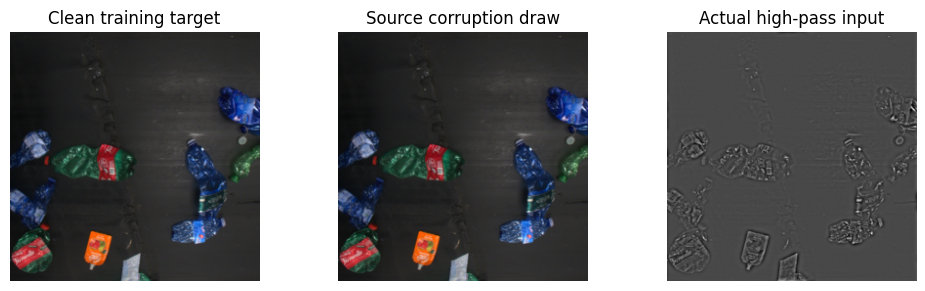

FAIR32_noDTD_WS2_100_policy | parameters: 4,322,307 | trained from scratch


In [3]:
def read_rgb(path):
    with Image.open(path) as im:
        return np.array(im.convert('RGB').resize((SIZE, SIZE), Image.Resampling.BILINEAR),
                        dtype=np.uint8, copy=True)

def cache_images(role):
    path = CACHE / f'images_{role}.npy'
    shape = (len(splits[role]), SIZE, SIZE, 3)
    if not path.exists():
        temp = path.with_name(path.stem + '.tmp.npy')
        a = np.lib.format.open_memmap(temp, mode='w+', dtype=np.uint8, shape=shape)
        for i, record in enumerate(tqdm(splits[role], desc='Resize ' + role)):
            a[i] = read_rgb(record['path'])
        a.flush()
        del a
        temp.replace(path)
    a = np.load(path, mmap_mode='r')
    if a.shape != shape or a.dtype != np.uint8:
        raise RuntimeError('Invalid image cache: ' + str(path))
    return a

def prepare_training_pngs():
    # Preserve upstream cv2 loading and all augmenters, while matching our PIL resize.
    rgb = cache_images('train')
    folder = CACHE / 'train_png'
    folder.mkdir(exist_ok=True)
    paths = [folder / f'{i:06d}.png' for i in range(len(rgb))]
    marker = folder / 'COMPLETE.json'
    expected = dict(data_sha256=config['data_sha256'], size=SIZE, count=len(paths))
    if not marker.exists():
        for i, p in enumerate(tqdm(paths, desc='Cache source-compatible training images')):
            Image.fromarray(np.asarray(rgb[i])).save(p, compress_level=1)
        write_json(marker, expected)
    if json.loads(marker.read_text()) != expected or not all(p.exists() for p in paths):
        raise RuntimeError('Training PNG cache incomplete; remove _cache/train_png and rerun.')
    return [str(p) for p in paths]

class WS2FAIRTrain(MVTecTrainDataset):
    def __init__(self, paths):
        super().__init__(root_dir='', anomaly_source_path='', resize_shape=[SIZE, SIZE])
        self.image_paths = list(paths)
        self.anomaly_source_paths = list(paths)
        assert len(self.image_paths) > 0

def seed_augmenters(dataset, seed):
    ia.seed(seed)
    for j, augmenter in enumerate(dataset.augmenters):
        augmenter.seed_(seed + j + 1)
    dataset.rot.seed_(seed + 100)

def worker_init(worker_id):
    seed = int(torch.initial_seed() % (2 ** 32))
    random.seed(seed)
    np.random.seed(seed)
    cv2.setNumThreads(0)
    seed_augmenters(torch.utils.data.get_worker_info().dataset, seed)

def make_train_loader(epoch):
    seed_all(SEED + epoch)
    seed_augmenters(train_dataset, SEED + epoch)
    return DataLoader(train_dataset, batch_size=BATCH, shuffle=True, drop_last=False,
                      num_workers=WORKERS, pin_memory=True, worker_init_fn=worker_init,
                      generator=torch.Generator().manual_seed(SEED + epoch),
                      persistent_workers=False)

def bhpf_bgr(bgr_float):
    # Same formula/order and NumPy FFT precision as the official loader.
    gray = cv2.cvtColor(np.asarray(bgr_float, dtype=np.float32), cv2.COLOR_BGR2GRAY)
    rows, cols = gray.shape
    crow, ccol = int(rows / 2), int(cols / 2)
    yy, xx = np.ogrid[:rows, :cols]
    dist = np.sqrt((xx - crow) ** 2 + (yy - ccol) ** 2)
    filt = 1 / (1 + (30 / (dist + 1e-6)) ** 4)
    filtered = np.fft.ifft2(np.fft.ifftshift(np.fft.fftshift(np.fft.fft2(gray)) * filt))
    return np.real(filtered).astype(np.float32)[None]

def cache_clean_hpf(role):
    rgb = cache_images(role)
    path = CACHE / f'clean_hpf_{role}.npy'
    shape = (len(rgb), 1, SIZE, SIZE)
    if not path.exists():
        temp = path.with_name(path.stem + '.tmp.npy')
        out = np.lib.format.open_memmap(temp, mode='w+', dtype=np.float32, shape=shape)
        for i in tqdm(range(len(rgb)), desc='High-pass ' + role):
            bgr = np.ascontiguousarray(rgb[i, :, :, ::-1], dtype=np.float32) / 255
            out[i] = bhpf_bgr(bgr)
        out.flush()
        del out
        temp.replace(path)
    a = np.load(path, mmap_mode='r')
    if a.shape != shape or a.dtype != np.float32:
        raise RuntimeError('Invalid high-pass cache')
    return a

def clean_batches(role, batch_size=EVAL_BATCH):
    rgb, hpf = cache_images(role), cache_clean_hpf(role)
    for start in range(0, len(rgb), batch_size):
        stop = min(start + batch_size, len(rgb))
        # The official training targets and decoder outputs use BGR ordering.
        target = torch.from_numpy(np.ascontiguousarray(rgb[start:stop, :, :, ::-1]))
        target = target.permute(0, 3, 1, 2).float().to(DEVICE) / 255
        inp = torch.from_numpy(np.array(hpf[start:stop], copy=True)).to(DEVICE)
        yield start, inp, target

train_dataset = WS2FAIRTrain(prepare_training_pngs())
cache_clean_hpf('select')
seed_all(SEED)
seed_augmenters(train_dataset, SEED)
example = train_dataset[0]
for key, shape in [('image', (3, SIZE, SIZE)), ('auggray', (1, SIZE, SIZE))]:
    assert example[key].shape == shape and np.isfinite(example[key]).all()
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(example['image'].transpose(1, 2, 0)[:, :, ::-1].clip(0, 1))
axes[0].set_title('Clean training target')
axes[1].imshow(example['augmented_image'].transpose(1, 2, 0)[:, :, ::-1].clip(0, 1))
axes[1].set_title('Source corruption draw')
axes[2].imshow(example['auggray'][0], cmap='gray')
axes[2].set_title('Actual high-pass input')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
fig.savefig(RUN / 'training_input_example.png', dpi=150)
plt.show()
del example

def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        m.weight.data.normal_(0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        m.weight.data.normal_(1.0, 0.02)
        m.bias.data.fill_(0)

class OfficialSSIMLoss(nn.Module):
    # Calls upstream ssim() unchanged. Avoid only SSIM.__init__'s hard-coded .cuda().
    def __init__(self):
        super().__init__()
        self.register_buffer('window', create_window(11, 3))

    def forward(self, reconstruction, target):
        score, _ = source_ssim(reconstruction, target, window_size=11,
                               window=self.window.to(reconstruction), size_average=True)
        return 1 - score

def native_score_bgr(reconstruction, target, msgms):
    # Preserve test.py's BGR -> rgb_to_lab behavior, including unbounded outputs.
    # This reproduces the released source's channel convention; it is not an RGB fix.
    rec_lab = kornia.color.rgb_to_lab(reconstruction)
    ori_lab = kornia.color.rgb_to_lab(target)
    color = (ori_lab - rec_lab).square()[:, 1:3].sum(dim=1, keepdim=True) * .0003
    score = msgms(reconstruction, target, as_loss=False) + color
    kernel = torch.ones(1, 1, 21, 21, device=score.device, dtype=score.dtype) / (21 ** 2)
    return F.conv2d(score, kernel, padding=10)

seed_all(SEED)
model = ReconstructiveSubNetwork(in_channels=1, out_channels=3, base_width=BASE_WIDTH).to(DEVICE)
model.apply(weights_init)
ssim_loss = OfficialSSIMLoss().to(DEVICE)
msgms = MSGMSLoss().to(DEVICE)
PARAMETERS = sum(p.numel() for p in model.parameters())
TRAINABLE_PARAMETERS = sum(p.numel() for p in model.parameters() if p.requires_grad)
with torch.inference_mode():
    model.eval()
    test_input = torch.zeros(1, 1, SIZE, SIZE, device=DEVICE)
    rec = model(test_input)
    assert rec.shape == (1, 3, SIZE, SIZE) and torch.isfinite(rec).all()
    native = native_score_bgr(rec, torch.zeros_like(rec), msgms)
    assert native.shape == (1, 1, SIZE, SIZE) and torch.isfinite(native).all()
del test_input, rec, native
write_json(RUN / 'model_provenance.json', dict(
    model=MODEL_LABEL, upstream='https://github.com/liutongkun/FAIR', commit=FAIR_COMMIT,
    source_sha256=SOURCE_HASHES, network_definitions='unchanged official model_unetskip.py',
    width=BASE_WIDTH, total_parameters=PARAMETERS, trainable_parameters=TRAINABLE_PARAMETERS,
    pretraining='none', external_texture_data='none',
    upstream_ssim='same ssim() mathematics; device-safe window wrapper',
    source_native_color_convention='BGR passed to rgb_to_lab, source behavior preserved',
))
(RUN / 'architecture.txt').write_text(str(model) + f'\nParameters: {PARAMETERS}\n')
print(MODEL_LABEL, '| parameters:', f'{PARAMETERS:,}', '| trained from scratch')

Network and objective: preserve the published method while adapting its data interface.

In [4]:
@torch.inference_mode()
def normal_validation():
    model.eval()
    squared, structural, count = 0., 0., 0
    for _, inp, target in clean_batches('select'):
        reconstruction = model(inp)
        mse = F.mse_loss(reconstruction, target)
        ssl = ssim_loss(reconstruction, target)
        if not bool(torch.isfinite(mse + ssl)):
            raise FloatingPointError('Nonfinite normal validation loss')
        squared += mse.item() * len(inp)
        structural += ssl.item() * len(inp)
        count += len(inp)
    return squared / count, structural / count

def resume_bundle():
    destination = RUN.parent / 'FAIR_baseline_7_100_policy_resume.zip'
    with zipfile.ZipFile(destination, 'w', zipfile.ZIP_STORED) as z:
        for name in ('config.json', 'last.pt', 'best.pt', 'training_history.csv', 'status.json'):
            p = RUN / name
            if p.exists():
                z.write(p, name)
    return destination

def optimizer_to_device(optimizer):
    # load_pt intentionally loads on CPU; momentum tensors must follow parameters.
    for param, state in optimizer.state.items():
        for key in ('exp_avg', 'exp_avg_sq', 'max_exp_avg_sq'):
            if key in state:
                state[key] = state[key].to(param.device)

optimizer = torch.optim.Adam(model.parameters(), lr=LR, betas=(.9, .999), eps=1e-8,
                             weight_decay=0, foreach=False)
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=[int(EPOCHS * .8), int(EPOCHS * .9)], gamma=.2)
history, completed, best, best_epoch = [], 0, float('inf'), 0
best_model_cpu = None
stop_anchor, stale_epochs = None, 0
if (RUN / 'last.pt').exists():
    state = load_pt(RUN / 'last.pt')
    if state['config_sha256'] != digest(config):
        raise RuntimeError('Checkpoint/config mismatch')
    model.load_state_dict(state['model'])
    optimizer.load_state_dict(state['optimizer'])
    optimizer_to_device(optimizer)
    scheduler.load_state_dict(state['scheduler'])
    history, completed, best, best_epoch = state['history'], state['epoch'], state['best'], state['best_epoch']
    best_model_cpu = state['best_model']
    stop_anchor, stale_epochs = state['stop_anchor'], int(state['stale_epochs'])
    # last.pt is the atomic commit for the epoch. Rebuild best.pt from it so a
    # timeout between writes cannot pair new best weights with old optimizer state.
    save_pt(dict(model=best_model_cpu, epoch=best_epoch, select_mse=best,
                 config_sha256=digest(config)), RUN / 'best.pt')
    selected_state = load_pt(RUN / 'best.pt')
    assert selected_state['epoch'] == best_epoch and selected_state['config_sha256'] == digest(config)
    del state, selected_state
    print('Resume after completed epoch', completed, '| best normal epoch', best_epoch)

def train_remaining():
    global history, completed, best, best_epoch, best_model_cpu, stop_anchor, stale_epochs
    session_start = time.monotonic()
    try:
        for epoch in range(completed + 1, EPOCHS + 1):
            if stale_epochs >= PATIENCE:
                break
            elapsed = time.monotonic() - session_start
            estimate = max([h['epoch_seconds'] for h in history[-3:]], default=0.)
            if elapsed > 0 and elapsed + estimate > SESSION_TRAINING_HOURS * 3600:
                print('Pausing at an epoch boundary to preserve Kaggle outputs.', flush=True)
                break
            begin = time.monotonic()
            model.train()
            totals = np.zeros(3, dtype=np.float64)
            count = 0
            lr_used = float(optimizer.param_groups[0]['lr'])
            loader = make_train_loader(epoch)
            for sample in tqdm(loader, desc=f'Train {epoch}/{EPOCHS}', leave=False):
                target = sample['image'].to(DEVICE, non_blocking=True)
                inp = sample['auggray'].to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                reconstruction = model(inp)
                mse = F.mse_loss(reconstruction, target)
                ssl = ssim_loss(reconstruction, target)
                loss = mse + ssl
                if not bool(torch.isfinite(loss)):
                    raise FloatingPointError(f'Training diverged at epoch {epoch}')
                loss.backward()
                optimizer.step()
                totals += np.array([loss.item(), mse.item(), ssl.item()]) * len(inp)
                count += len(inp)
            assert count == len(train_dataset)
            val_mse, val_ssim = (normal_validation() if epoch == 1 or epoch % VALIDATE_EVERY == 0
                                 or epoch == EPOCHS else (None, None))
            if val_mse is not None and val_mse < best:
                best, best_epoch = float(val_mse), epoch
                best_model_cpu = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                save_pt(dict(model=best_model_cpu, epoch=epoch, select_mse=best,
                             config_sha256=digest(config)), RUN / 'best.pt')
            stop_anchor, stale_epochs = advance_stopping(val_mse, stop_anchor, stale_epochs)
            scheduler.step()
            seconds = time.monotonic() - begin
            history.append(dict(epoch=epoch, train_objective=float(totals[0] / count),
                                train_mse=float(totals[1] / count), train_ssim_loss=float(totals[2] / count),
                                select_mse=val_mse, select_ssim_loss=val_ssim, lr=lr_used,
                                best_epoch=best_epoch, epoch_seconds=seconds, sampled_frames=count,
                                optimizer_steps=len(loader), stopping_anchor=stop_anchor, stale_epochs=stale_epochs))
            completed = epoch
            save_pt(dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                         scheduler=scheduler.state_dict(), epoch=completed, best=best,
                         best_epoch=best_epoch, best_model=best_model_cpu, history=history,
                         stop_anchor=stop_anchor, stale_epochs=stale_epochs,
                         config_sha256=digest(config)), RUN / 'last.pt')
            save_pt(dict(model=best_model_cpu, epoch=best_epoch, select_mse=best,
                         config_sha256=digest(config)), RUN / 'best.pt')
            pd.DataFrame(history).to_csv(RUN / 'training_history.csv', index=False)
            write_json(RUN / 'status.json', dict(status='training', completed_epochs=completed,
                                                required_epochs=EPOCHS, test_evaluated=False))
            print(f'Epoch {epoch}/{EPOCHS}: loss={totals[0]/count:.6f}, MSE={totals[1]/count:.6f}, '
                  f'SSIMloss={totals[2]/count:.6f}, select_MSE={val_mse}, best={best_epoch}, '
                  f'lr={lr_used:g}, stale={stale_epochs}/{PATIENCE}, time={seconds:.1f}s', flush=True)
            if epoch == 1 or epoch % 10 == 0:
                remaining = np.mean([h['epoch_seconds'] for h in history[-10:]]) * (EPOCHS - epoch) / 3600
                print(f'Estimated remaining training: {remaining:.2f} hours (measured on this GPU).', flush=True)
            if stale_epochs >= PATIENCE:
                print('Normal-only early stopping reached; restore the absolute best checkpoint.')
                break
    except BaseException:
        # last.pt always refers to a fully completed epoch; partial epochs are replayed.
        report_zip()
        if (RUN / 'last.pt').exists():
            resume_bundle()
        raise

train_remaining()
TRAINING_COMPLETE = completed == EPOCHS or stale_epochs >= PATIENCE
write_training_metadata()

Train 1/100:   0%|          | 0/479 [00:00<?, ?it/s]

Epoch 1/100: loss=0.183696, MSE=0.009580, SSIMloss=0.174116, select_MSE=0.004429165009344837, best=1, lr=0.0001, stale=0/10, time=97.8s
Estimated remaining training: 2.69 hours (measured on this GPU).


Train 2/100:   0%|          | 0/479 [00:00<?, ?it/s]

Epoch 2/100: loss=0.111374, MSE=0.005322, SSIMloss=0.106052, select_MSE=0.003508427996374309, best=2, lr=0.0001, stale=0/10, time=101.6s


Train 3/100:   0%|          | 0/479 [00:00<?, ?it/s]

...

Train 17/100:   0%|          | 0/479 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a7d80bf0220>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a7d80bf0220>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

Epoch 17/100: loss=0.069673, MSE=0.003578, SSIMloss=0.066094, select_MSE=0.002592564777662395, best=8, lr=0.0001, stale=9/10, time=132.2s


Train 18/100:   0%|          | 0/479 [00:00<?, ?it/s]

Epoch 18/100: loss=0.069155, MSE=0.003494, SSIMloss=0.065662, select_MSE=0.0029087857371857553, best=8, lr=0.0001, stale=10/10, time=101.8s
Normal-only early stopping reached; restore the absolute best checkpoint.


Normal-only training: optimizer, validation, atomic recovery and checkpoint selection.

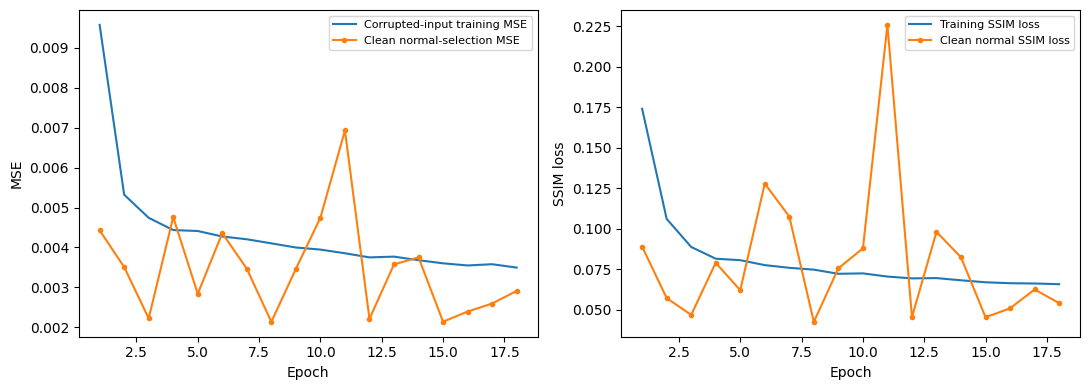

PosixPath('/kaggle/working/FAIR_baseline_7_100_policy_report.zip')

In [5]:
if TRAINING_COMPLETE:
    save_pt(dict(model=model.state_dict(), epoch=completed, config_sha256=digest(config)), RUN / 'final.pt')
    selected = load_pt(RUN / 'best.pt')
    model.load_state_dict(selected['model'])
    model.eval()
    write_json(RUN / 'selected_checkpoint.json', dict(
        epoch=int(selected['epoch']), select_mse=float(selected['select_mse']),
        sha256=sha(RUN / 'best.pt'), trained_epochs=completed, max_epochs=EPOCHS, early_stopped=stale_epochs >= PATIENCE,
        selection='normal MSE; test labels never used',
    ))
    del selected
else:
    write_json(RUN / 'status.json', dict(status='paused_for_resume', completed_epochs=completed,
                                        required_epochs=EPOCHS, test_evaluated=False))
    print('Training is incomplete. Later cells will skip calibration/test evaluation.')
    print('Save notebook output, attach it to the next session, set RESUME_DIR, and Run All.')
    display(FileLink(str(resume_bundle())))
history_df = pd.DataFrame(history)
if len(history_df):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history_df.epoch, history_df.train_mse, label='Corrupted-input training MSE')
    v = history_df.dropna(subset=['select_mse'])
    axes[0].plot(v.epoch, v.select_mse, 'o-', label='Clean normal-selection MSE', markersize=3)
    axes[0].set(xlabel='Epoch', ylabel='MSE')
    axes[0].legend(fontsize=8)
    axes[1].plot(history_df.epoch, history_df.train_ssim_loss, label='Training SSIM loss')
    axes[1].plot(v.epoch, v.select_ssim_loss, 'o-', label='Clean normal SSIM loss', markersize=3)
    axes[1].set(xlabel='Epoch', ylabel='SSIM loss')
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(RUN / 'training_curve.png', dpi=150)
    plt.show()
report_zip()

Locked evaluation: threshold calibration, residual maps, full metrics and report export.

In [6]:
STRUCT = generate_binary_structure(2, 2)

def postprocess(mask):
    m = binary_closing(mask, structure=STRUCT, iterations=2)
    m = binary_opening(m, structure=STRUCT, iterations=1)
    m = binary_fill_holes(m)
    cc, _ = label(m)
    keep = np.bincount(cc.ravel()) >= 50
    keep[0] = False
    return binary_opening(keep[cc], structure=STRUCT, iterations=2)

@torch.inference_mode()
def score_maps(role):
    model.eval()
    paths = {s: MAP_DIR / f'{s}_{role}.npy' for s in SCORES}
    shape = (len(splits[role]), SIZE, SIZE)
    if not all(p.exists() for p in paths.values()):
        temps = {s: p.with_name(p.stem + '.tmp.npy') for s, p in paths.items()}
        arr = {s: np.lib.format.open_memmap(p, mode='w+', dtype=np.float32, shape=shape)
               for s, p in temps.items()}
        begin = time.monotonic()
        native_seconds = 0.
        total_batches = math.ceil(len(splits[role]) / EVAL_BATCH)
        for start, inp, target in tqdm(clean_batches(role), total=total_batches, desc='Score ' + role):
            rec = model(inp)
            mae = (target - rec).abs().mean(dim=1).cpu().numpy()
            # MAE is invariant to applying the same RGB/BGR channel permutation to both.
            for j, a in enumerate(mae):
                arr['shared_mae'][start + j] = gaussian_filter(a, sigma=1)
            tick = time.monotonic()
            native = native_score_bgr(rec, target, msgms)[:, 0].cpu().numpy()
            native_seconds += time.monotonic() - tick
            arr['fair_native_source'][start:start + len(native)] = native
        for a in arr.values():
            a.flush()
        del a
        arr.clear()
        for s in SCORES:
            temps[s].replace(paths[s])
        write_json(RUN / f'scoring_runtime_{role}.json', dict(
            frames=shape[0], combined_seconds=time.monotonic() - begin,
            native_score_seconds=native_seconds, evaluation_batch=EVAL_BATCH,
            description='includes cache reads, reconstruction and both scores; not pure model FPS',
        ))
    result = {s: np.load(p, mmap_mode='r') for s, p in paths.items()}
    for a in result.values():
        assert a.shape == shape and a.dtype == np.float32
        for frame in a:
            if not np.isfinite(frame).all():
                raise FloatingPointError('Nonfinite score map')
    return result

def calibrate_scores():
    maps = {role: score_maps(role) for role in ('select', 'calibrate', 'audit')}
    thresholds, audit_rows = {}, []
    for s in SCORES:
        vals = np.concatenate([maps[r][s].ravel() for r in ('select', 'calibrate', 'audit')])
        q1, q3 = np.percentile(vals, [25, 75])
        thresholds[s] = {'historical': float(q3 + 4 * (q3 - q1))}
        del vals
        rng = np.random.default_rng(SEED + 71)
        sample = np.concatenate([a.ravel()[rng.choice(SIZE * SIZE, 4096, replace=False)]
                                 for a in maps['calibrate'][s]])
        for f in FPRS:
            thresholds[s][f'fpr_{f:g}'] = float(np.quantile(sample, 1 - f, method='higher'))
        for protocol, t in thresholds[s].items():
            raw, post = [], []
            for a in maps['audit'][s]:
                pred = a > t
                raw.append(float(pred.mean()))
                post.append(float(postprocess(pred).mean()))
            audit_rows.append(dict(score=s, protocol=protocol, threshold=t,
                                   audit_raw_fpr=float(np.mean(raw)), audit_post_fpr=float(np.mean(post)),
                                   audit_used_in_threshold=(protocol == 'historical')))
    write_json(RUN / 'thresholds_LOCKED.json', thresholds)
    audit = pd.DataFrame(audit_rows)
    audit.to_csv(RUN / 'normal_fpr.csv', index=False)
    write_json(RUN / 'evaluation_lock.json', dict(
        checkpoint_sha256=sha(RUN / 'best.pt'), config_sha256=digest(config),
        thresholds_sha256=sha(RUN / 'thresholds_LOCKED.json'), test_masks_decoded=False,
    ))
    return maps, thresholds, audit

Locked evaluation: threshold calibration, residual maps, full metrics and report export.

In [7]:
if TRAINING_COMPLETE:
    MAP_DIR = CACHE / ('scores_' + sha(RUN / 'best.pt')[:16])
    MAP_DIR.mkdir(exist_ok=True)
    maps, thresholds, audit = calibrate_scores()
    print('Model and thresholds locked. Test masks have not been decoded.')
    display(audit)

def confusion(pred, target):
    return (int(np.count_nonzero(pred & target)), int(np.count_nonzero(pred & ~target)),
            int(np.count_nonzero(~pred & target)), int(np.count_nonzero(~pred & ~target)))

def iou(tp, fp, fn):
    return tp / (tp + fp + fn) if tp + fp + fn else 1.0

def dice(tp, fp, fn):
    return 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 1.0

def pixel_ranking(scores, masks):
    # Exact AP/AUROC, with tied scores grouped, using a single sorting pass.
    # PRO gives every 8-connected GT region equal weight, integrates FPR<=0.30,
    # and normalizes by 0.30. Test labels here calculate metrics, not thresholds.
    y = np.asarray(masks, dtype=np.bool_).ravel()
    score = np.asarray(scores, dtype=np.float32).ravel()
    positives, negatives = int(y.sum()), int((~y).sum())
    if positives == 0 or negatives == 0:
        return dict(pixel_ap=None, pixel_auroc=None, pixel_aupro_0p30=None,
                    gt_regions=0, positive_pixels=positives, negative_pixels=negatives)
    weights = np.zeros(masks.shape, dtype=np.float32)
    regions = 0
    for i, m in enumerate(masks):
        cc, n = label(m, structure=STRUCT)
        areas = np.bincount(cc.ravel())
        lookup = np.zeros(len(areas), dtype=np.float32)
        lookup[1:] = 1. / areas[1:]
        weights[i] = lookup[cc]
        regions += n
    order = np.argsort(score, kind='stable')[::-1]
    sorted_scores = score[order]
    ends = np.r_[np.flatnonzero(np.diff(sorted_scores)), len(score) - 1]
    del sorted_scores
    cumsum = np.cumsum(y[order], dtype=np.int64)
    tp = cumsum[ends].astype(np.float64)
    del cumsum
    fp = (ends + 1).astype(np.float64) - tp
    ap = float(np.sum(np.diff(np.r_[0., tp]) * (tp / (ends + 1))) / positives)
    fpr = np.r_[0., fp / negatives]
    tpr = np.r_[0., tp / positives]
    trapz = getattr(np, 'trapezoid', None) or np.trapz
    auroc = float(trapz(tpr, fpr))
    del tp, fp, tpr
    region_cumsum = np.cumsum(weights.ravel()[order], dtype=np.float64)
    pro = np.r_[0., region_cumsum[ends] / regions]
    del region_cumsum, weights, order, ends
    cap = .30
    # Keep all vertical segments at a repeated FPR; interpolate the crossing segment.
    right = int(np.searchsorted(fpr, cap, side='right'))
    xx, yy = fpr[:right], pro[:right]
    if xx[-1] < cap:
        upper = right
        endpoint = yy[-1] + (pro[upper] - yy[-1]) * (cap - xx[-1]) / (fpr[upper] - xx[-1])
        xx = np.r_[xx, cap]
        yy = np.r_[yy, endpoint]
    aupro = float(trapz(yy, xx) / cap)
    return dict(pixel_ap=ap, pixel_auroc=auroc, pixel_aupro_0p30=aupro,
                gt_regions=int(regions), positive_pixels=positives, negative_pixels=negatives)

def evaluate_test():
    # Check the lock before accessing any test label content.
    lock = json.loads((RUN / 'evaluation_lock.json').read_text())
    assert lock['checkpoint_sha256'] == sha(RUN / 'best.pt')
    assert lock['thresholds_sha256'] == sha(RUN / 'thresholds_LOCKED.json')
    maps['test'] = score_maps('test')
    gt = np.lib.format.open_memmap(CACHE / 'test_masks.npy', mode='w+', dtype=np.bool_,
                                 shape=(len(splits['test']), SIZE, SIZE))
    mask_hashes = []
    for i, r in enumerate(tqdm(splits['test'], desc='Decode test masks after lock')):
        with Image.open(r['mask']) as im:
            gt[i] = np.asarray(im.convert('L').resize((SIZE, SIZE), Image.Resampling.BILINEAR),
                               dtype=np.float32) / 255 > .5
        mask_hashes.append(dict(relative=r['relative'], sha256=sha(r['mask'])))
    gt.flush()
    assert gt.any() and not gt.all()
    write_json(RUN / 'mask_hashes.json', mask_hashes)
    rows = []
    for s in SCORES:
        for protocol, t in tqdm(thresholds[s].items(), desc='Masks ' + s):
            for i, r in enumerate(splits['test']):
                raw = maps['test'][s][i] > t
                for processing, pred in [('raw', raw), ('postprocessed', postprocess(raw))]:
                    tp, fp, fn, tn = confusion(pred, gt[i])
                    rows.append(dict(score=s, protocol=protocol, processing=processing,
                                     relative=r['relative'], video=r['video'], tp=tp, fp=fp, fn=fn, tn=tn,
                                     iou=iou(tp, fp, fn), dice=dice(tp, fp, fn),
                                     precision=tp / (tp + fp) if tp + fp else 0.,
                                     recall=tp / (tp + fn) if tp + fn else 0.))
    frames = pd.DataFrame(rows)
    frames.to_csv(RUN / 'test_frame_metrics.csv', index=False)
    keys = ['score', 'protocol', 'processing']
    summaries = []
    for (s, protocol, processing), group in frames.groupby(keys, sort=False):
        tp, fp, fn, tn = [int(group[c].sum()) for c in ('tp', 'fp', 'fn', 'tn')]
        a = audit[(audit.score == s) & (audit.protocol == protocol)].iloc[0]
        summaries.append(dict(
            model=MODEL_LABEL, score=s, protocol=protocol, processing=processing,
            mean_frame_iou=float(group.iou.mean()), mean_iou=float(group.iou.mean()),
            median_frame_iou=float(group.iou.median()), mean_frame_dice=float(group.dice.mean()),
            mean_frame_precision=float(group.precision.mean()), mean_frame_recall=float(group.recall.mean()),
            pooled_iou=iou(tp, fp, fn), pooled_dice=dice(tp, fp, fn),
            pooled_precision=tp / (tp + fp) if tp + fp else 0.,
            pooled_recall=tp / (tp + fn) if tp + fn else 0.,
            audit_raw_fpr=float(a.audit_raw_fpr), audit_post_fpr=float(a.audit_post_fpr),
            audit_used_in_threshold=bool(a.audit_used_in_threshold), threshold=float(a.threshold),
            n_frames=len(group), total_parameters=PARAMETERS, trainable_parameters=PARAMETERS, selected_epoch=best_epoch, actual_epochs=completed, max_epochs=EPOCHS,
        ))
    summary = pd.DataFrame(summaries)
    summary.to_csv(RUN / 'summary.csv', index=False)
    frames.groupby(keys + ['video'], as_index=False).agg(
        mean_frame_iou=('iou', 'mean'), mean_frame_dice=('dice', 'mean'),
        frames=('iou', 'size')).to_csv(RUN / 'test_video_metrics.csv', index=False)
    ranking = []
    for s in SCORES:
        print('Exact full-pixel AP / AUROC / AUPRO:', s, flush=True)
        ranking.append(dict(score=s, **pixel_ranking(maps['test'][s], gt)))
    image_y=np.any(gt,axis=(1,2))
    image_rows=[]
    for s in SCORES:
        image_score=np.max(maps['test'][s],axis=(1,2))
        has_both=bool(image_y.any() and (~image_y).any())
        image_rows.append(dict(score=s,image_ap=float(average_precision_score(image_y,image_score)) if has_both else None,image_auroc=float(roc_auc_score(image_y,image_score)) if has_both else None,n_normal_images=int((~image_y).sum()),n_anomalous_images=int(image_y.sum()),image_score='maximum native map value',undefined_reason=None if has_both else 'Test split does not contain both normal and anomalous images'))
    write_json(RUN/'image_ranking.json',image_rows)
    ranking = pd.DataFrame(ranking)
    ranking.to_csv(RUN / 'full_pixel_ranking.csv', index=False)
    headline = summary[(summary.processing == 'postprocessed') &
                       summary.protocol.isin(['historical', 'fpr_0.02'])].merge(ranking, on='score')
    headline.to_csv(RUN / 'headline_metrics.csv', index=False)
    print('Primary historical comparison: shared_mae / historical / postprocessed / mean_frame_iou')
    display(headline[['score', 'protocol', 'mean_frame_iou', 'mean_frame_dice',
                      'pooled_precision', 'pooled_recall', 'pixel_ap', 'pixel_auroc', 'audit_post_fpr']])
    return gt, frames, summary, ranking, headline

Score select:   0%|          | 0/66 [00:00<?, ?it/s]

Score calibrate:   0%|          | 0/16 [00:00<?, ?it/s]

Resize calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

High-pass calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Score audit:   0%|          | 0/30 [00:00<?, ?it/s]

Resize audit:   0%|          | 0/234 [00:00<?, ?it/s]

High-pass audit:   0%|          | 0/234 [00:00<?, ?it/s]

Model and thresholds locked. Test masks have not been decoded.


,score,protocol,threshold,audit_raw_fpr,audit_post_fpr,audit_used_in_threshold
0,shared_mae,historical,0.106089,0.052193,0.046218,True
1,shared_mae,fpr_0.005,0.206957,0.008621,0.006749,False
2,shared_mae,fpr_0.01,0.174031,0.016308,0.013760,False
3,shared_mae,fpr_0.02,0.132177,0.033860,0.029775,False
4,shared_mae,fpr_0.05,0.081383,0.081313,0.073835,False
5,shared_mae,fpr_0.1,0.052757,0.150902,0.146041,False
6,fair_native_source,historical,0.212614,0.095791,0.094552,True
7,fair_native_source,fpr_0.005,1.128113,0.005180,0.005028,False
8,fair_native_source,fpr_0.01,0.734268,0.013153,0.012853,False
9,fair_native_source,fpr_0.02,0.479111,0.030197,0.029661,False


Locked evaluation: threshold calibration, residual maps, full metrics and report export.

In [8]:
if TRAINING_COMPLETE:
    gt, frames, summary, ranking, headline = evaluate_test()

@torch.inference_mode()
def reconstruct_rgb(rgb):
    bgr = np.ascontiguousarray(rgb[:, :, ::-1], dtype=np.float32) / 255
    inp = torch.from_numpy(bhpf_bgr(bgr)[None]).to(DEVICE)
    rec = model(inp)[0].permute(1, 2, 0).cpu().numpy()
    return rec[:, :, ::-1].copy()

def final_report():
    fig, ax = plt.subplots(figsize=(7, 4))
    for s in SCORES:
        d = summary[(summary.score == s) & (summary.processing == 'postprocessed') &
                    (summary.protocol != 'historical')].sort_values('audit_raw_fpr')
        ax.plot(d.audit_raw_fpr, d.mean_frame_iou, 'o-', label=s)
    ax.set(xlabel='Achieved independent normal-audit pixel FPR before morphology',
           ylabel='Test mean per-frame anomaly IoU')
    ax.legend()
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(RUN / 'iou_vs_fpr.png', dpi=150)
    plt.show()

    indices = np.linspace(0, len(splits['test']) - 1, 3, dtype=int)
    data = cache_images('test')
    for protocol in ('historical', 'fpr_0.02'):
        fig, axes = plt.subplots(3, 7, figsize=(21, 10))
        for row, idx in enumerate(indices):
            rec = reconstruct_rgb(data[idx])
            t1 = thresholds['shared_mae'][protocol]
            t2 = thresholds['fair_native_source'][protocol]
            panels = [
                (data[idx], 'Input', None, None),
                (np.clip(rec, 0, 1), 'Reconstruction (display clipped)', None, None),
                (gt[idx], 'Ground truth', 'gray', None),
                (maps['test']['shared_mae'][idx], 'Shared MAE', 'inferno', max(2 * t1, 1e-8)),
                (postprocess(maps['test']['shared_mae'][idx] > t1), 'Shared MAE mask', 'gray', None),
                (maps['test']['fair_native_source'][idx], 'FAIR source score', 'inferno', max(2 * t2, 1e-8)),
                (postprocess(maps['test']['fair_native_source'][idx] > t2), 'FAIR source mask', 'gray', None),
            ]
            for col, (a, title, cmap, vmax) in enumerate(panels):
                axes[row, col].imshow(a, cmap=cmap, vmin=0 if vmax else None, vmax=vmax)
                axes[row, col].set_title(title, fontsize=9)
                axes[row, col].axis('off')
        fig.suptitle(f'{MODEL_LABEL}; fixed manifest frames; {protocol}; shared morphology')
        fig.tight_layout()
        fig.savefig(RUN / f'fixed_examples_{protocol}.png', dpi=150)
        plt.show()
    write_json(RUN / 'fixed_examples.json', [splits['test'][int(i)]['relative'] for i in indices])
    status = dict(status='complete', model=MODEL_LABEL, completed_epochs=completed, required_epochs=EPOCHS,
                  selected_epoch=best_epoch, parameters=PARAMETERS, test_evaluated=True,
                  cumulative_training_seconds=float(history_df.epoch_seconds.sum()),
                  cumulative_optimizer_steps=int(history_df.optimizer_steps.sum()))
    status.update(max_epochs=EPOCHS,early_stopped=stale_epochs >= PATIENCE)
    write_training_metadata()
    write_json(RUN / 'status.json', status)
    report_text = f'''{MODEL_LABEL}\n\nFull benchmark complete.\n
Primary controlled result: summary.csv, score=shared_mae, protocol=historical,
processing=postprocessed, column=mean_frame_iou (mean_iou is an identical alias).
Compare only to Christian/QMem/repair results under the SAME historical protocol.
Historical calibration includes all normal validation frames, including audit.
The fpr_* protocols use calibration only; their normal-audit FPR is independent.
Do not compare an fpr_* IoU directly with a historical IoU as if protocols matched.

FAIR source-native scoring is reported separately. It uses MSGMS plus Lab colour
differences and the official 21x21 box smoothing, with source BGR handling retained.
Shared MAE uses only channel-mean absolute reconstruction error plus sigma-1 Gaussian
smoothing. RGB/BGR permutation does not affect this channel average.
No reconstruction clipping is applied for either score.

Network, augmentations, MSE and SSIM are from the pinned official repository.
Width {BASE_WIDTH}, maximum {EPOCHS} epochs (actual {completed}), clean normal MSE selection, seed control,
PIL input resizing, and shared threshold/mask evaluation are declared WS2 adaptations.
The official 800-epoch MVTec recipe is not being claimed for this run.
No external images, pretrained features, anomaly labels, SAM or classifier are used.

Both raw-threshold and morphology-processed masks are saved in metric CSVs.
Mean-frame IoU/Dice assign 1 to an empty prediction with an empty target.
Precision/recall use 0 when their denominators are empty; pooled values are separate.
Pixel AP/AUROC/AUPRO use full continuous maps BEFORE binary morphology.
AUPRO averages 8-connected GT regions equally, integrates to FPR=0.30, then divides
by 0.30; it is computed from all score thresholds with tied scores grouped.

One training seed. No claim of significance or superiority should be made from a
single run alone. The historical test set was already inspected in prior research.
Keep all results, including unfavourable scores. Do not select the score by test IoU.

Send FAIR_baseline_7_100_policy_report.zip and the executed notebook/log.
Keep best.pt, final.pt, last.pt and FAIR_baseline_7_100_policy_resume.zip for reproducibility.
Large _cache/*.npy files are not needed for initial analysis.
'''
    (RUN / 'REPORT.txt').write_text(report_text)
    print(report_text)

Score test:   0%|          | 0/62 [00:00<?, ?it/s]

Resize test:   0%|          | 0/496 [00:00<?, ?it/s]

High-pass test:   0%|          | 0/496 [00:00<?, ?it/s]

Decode test masks after lock:   0%|          | 0/496 [00:00<?, ?it/s]

Masks shared_mae:   0%|          | 0/6 [00:00<?, ?it/s]

Masks fair_native_source:   0%|          | 0/6 [00:00<?, ?it/s]

Exact full-pixel AP / AUROC / AUPRO: shared_mae
Exact full-pixel AP / AUROC / AUPRO: fair_native_source
Primary historical comparison: shared_mae / historical / postprocessed / mean_frame_iou


,score,protocol,mean_frame_iou,mean_frame_dice,pooled_precision,pooled_recall,pixel_ap,pixel_auroc,audit_post_fpr
0,shared_mae,historical,0.170379,0.283277,0.308381,0.293894,0.262715,0.592515,0.046218
1,shared_mae,fpr_0.02,0.145117,0.245242,0.461918,0.182989,0.262715,0.592515,0.029775
2,fair_native_source,historical,0.155809,0.260411,0.273052,0.286139,0.263844,0.740673,0.094552
3,fair_native_source,fpr_0.02,0.070401,0.123963,0.301627,0.091670,0.263844,0.740673,0.029661


Locked evaluation: threshold calibration, residual maps, full metrics and report export.

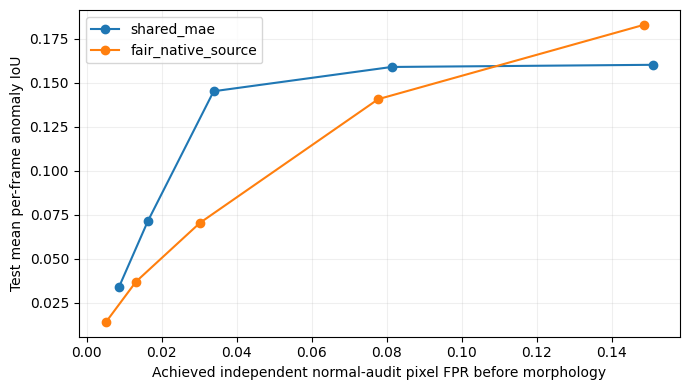

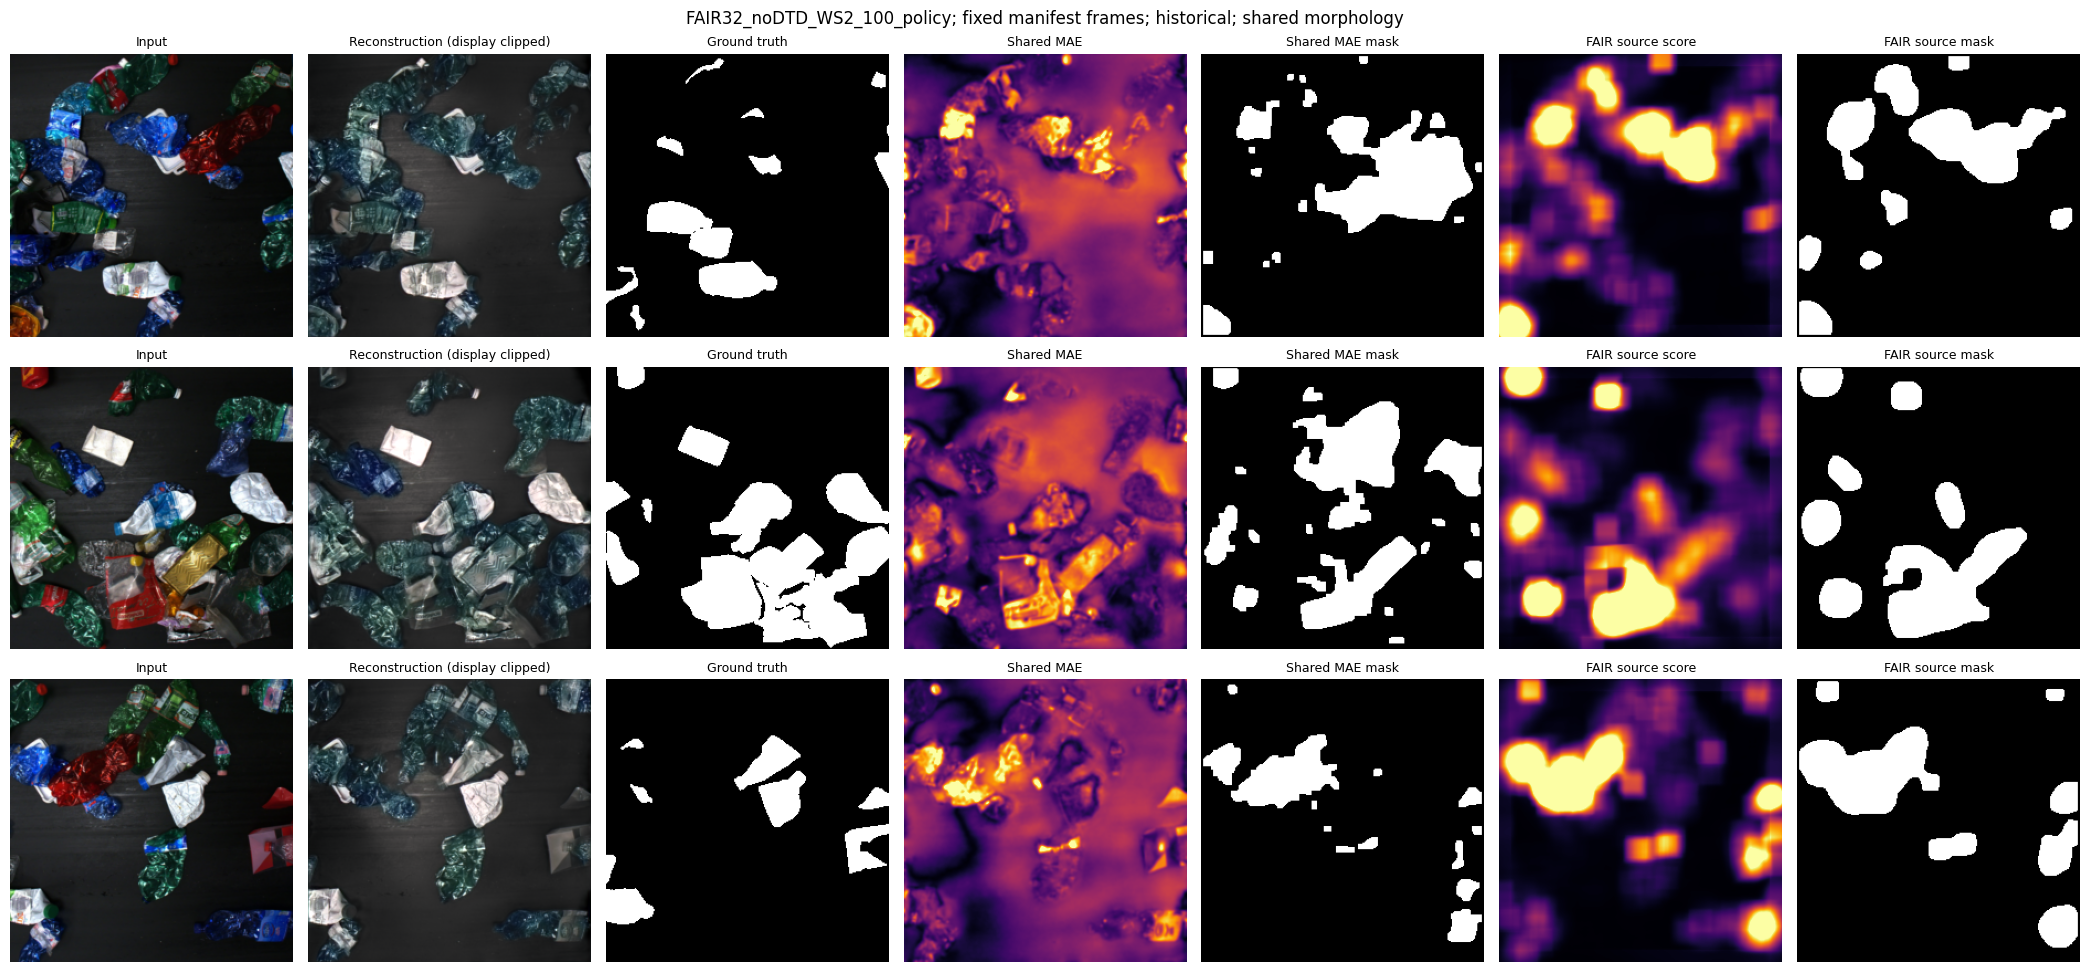

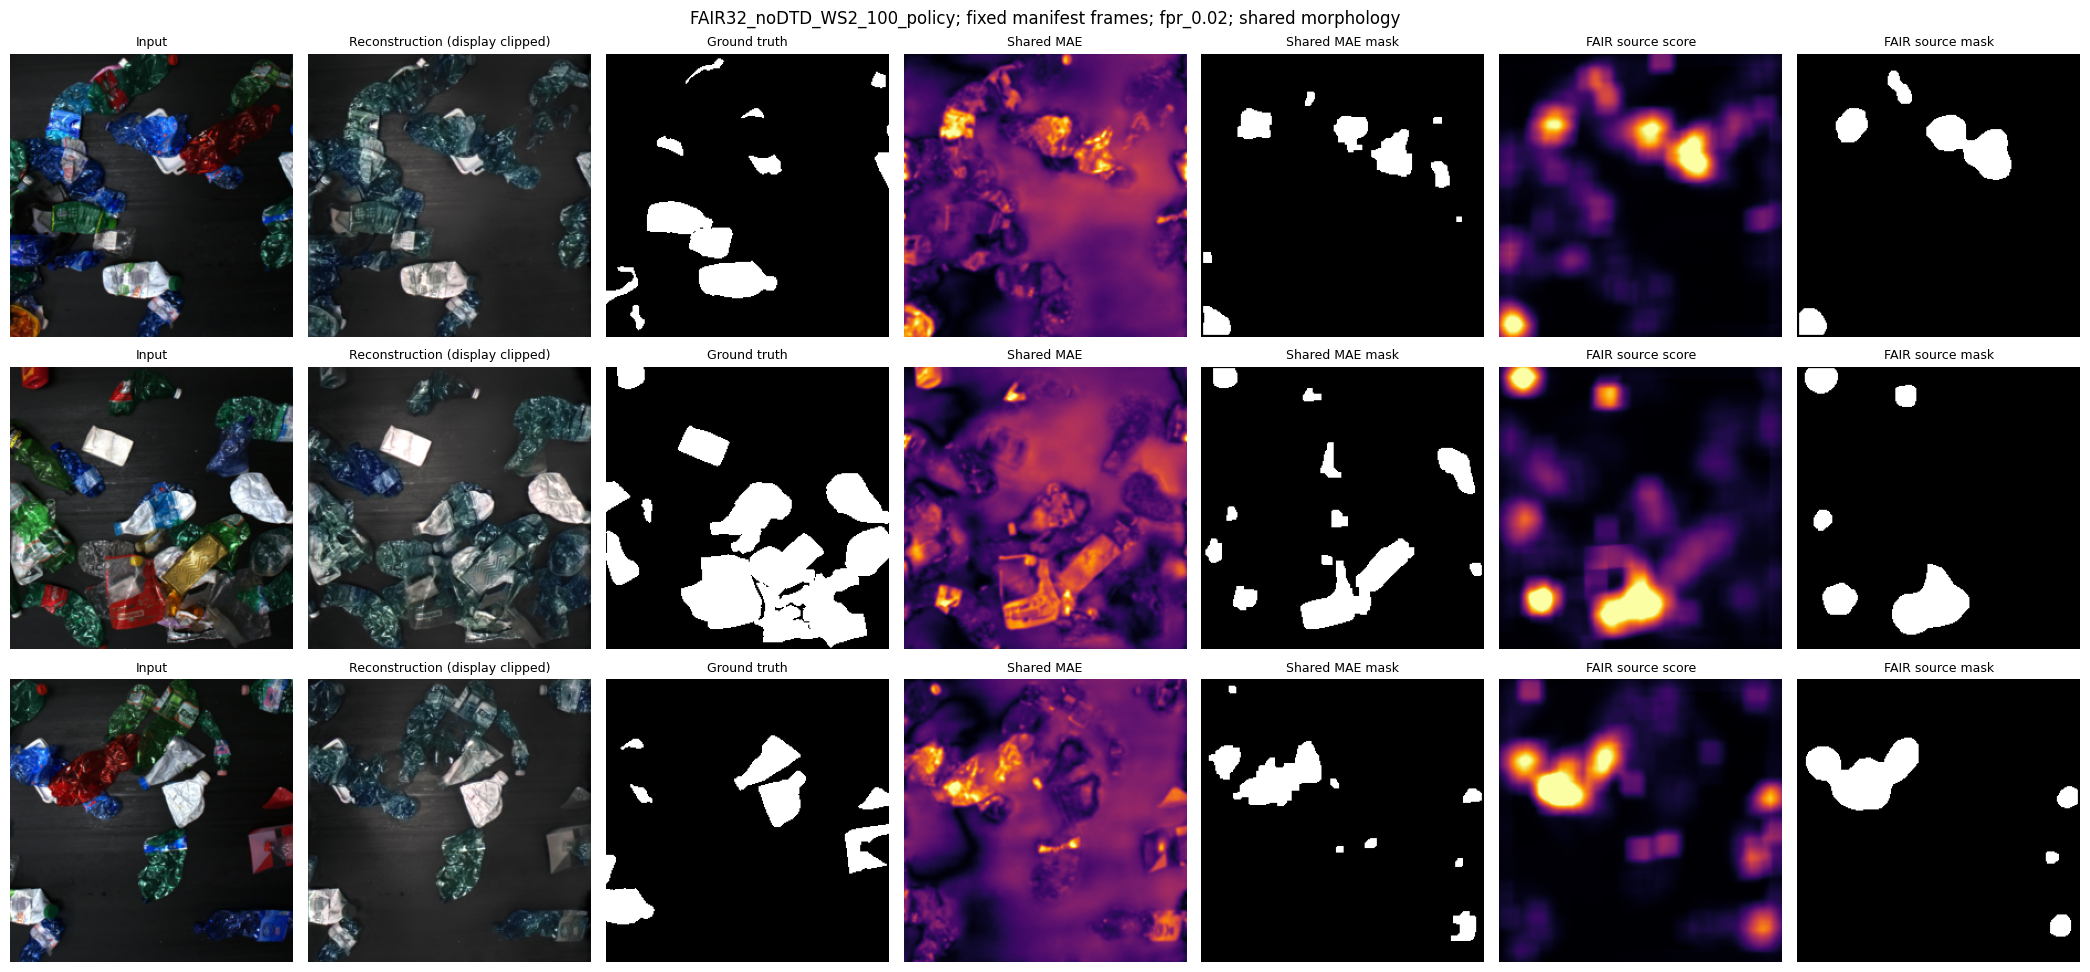

FAIR32_noDTD_WS2_100_policy

Full benchmark complete.

Primary controlled result: summary.csv, score=shared_mae, protocol=historical,
processing=postprocessed, column=mean_frame_iou (mean_iou is an identical alias).
Compare only to Christian/QMem/repair results under the SAME historical protocol.
Historical calibration includes all normal validation frames, including audit.
The fpr_* protocols use calibration only; their normal-audit FPR is independent.
Do not compare an fpr_* IoU directly with a historical IoU as if protocols matched.

FAIR source-native scoring is reported separately. It uses MSGMS plus Lab colour
differences and the official 21x21 box smoothing, with source BGR handling retained.
Shared MAE uses only channel-mean absolute reconstruction error plus sigma-1 Gaussian
smoothing. RGB/BGR permutation does not affect this channel average.
No reconstruction clipping is applied for either score.

Network, augmentations, MSE and SSIM are from the pinned official repository.
W

/kaggle/working/FAIR_baseline_7_100_policy_report.zip

/kaggle/working/FAIR_baseline_7_100_policy_resume.zip

Keep checkpoints in: /kaggle/working/FAIR_baseline_7_100_policy


In [9]:
if TRAINING_COMPLETE:
    final_report()
try:
    (RUN / 'executed_cells.py').write_text('\n\n'.join(get_ipython().history_manager.input_hist_raw))
except (NameError, AttributeError):
    pass
report = report_zip()
display(FileLink(str(report)))
if (RUN / 'last.pt').exists():
    display(FileLink(str(resume_bundle())))
print('Keep checkpoints in:', RUN)